In [1]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation, genome, track_data, transcript
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
API_KEY = "***REMOVED***"

dna_model = dna_client.create(API_KEY)

In [3]:
[output.name for output in dna_client.OutputType]

['ATAC',
 'CAGE',
 'DNASE',
 'RNA_SEQ',
 'CHIP_HISTONE',
 'CHIP_TF',
 'SPLICE_SITES',
 'SPLICE_SITE_USAGE',
 'SPLICE_JUNCTIONS',
 'CONTACT_MAPS',
 'PROCAP']

In [4]:
output_metadata = dna_model.output_metadata(
    organism=dna_client.Organism.HOMO_SAPIENS
)

In [5]:
# Load gene annotations (from GENCODE).
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Filter to protein-coding genes and highly supported transcripts.
gtf_transcript = gene_annotation.filter_transcript_support_level(
    gene_annotation.filter_protein_coding(gtf), ['1']
)

# Extractor for identifying transcripts in a region.
transcript_extractor = transcript.TranscriptExtractor(gtf_transcript)

# Also define an extractor that fetches only the longest transcript per gene.
gtf_longest_transcript = gene_annotation.filter_to_longest_transcript(
    gtf_transcript
)
longest_transcript_extractor = transcript.TranscriptExtractor(
    gtf_longest_transcript
)

In [6]:
# Define interval to make predictions for (used throughout this tutorial).
# Note that the interval width must be one of the supported sequence lengths.
interval = genome.Interval('chr22', 36_150_498, 36_252_898).resize(
    dna_client.SEQUENCE_LENGTH_1MB
)

# Define the tissues/cell-types to predict expression for.
ontology_terms = [
    'UBERON:0001159',  # Colon - Sigmoid.
    'UBERON:0001155',  # Colon - Transverse.
]

# Make predictions.
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.CAGE,
    },
    ontology_terms=ontology_terms,
)

# Extract the longest transcripts per gene for this interval.
longest_transcripts = longest_transcript_extractor.extract(interval)

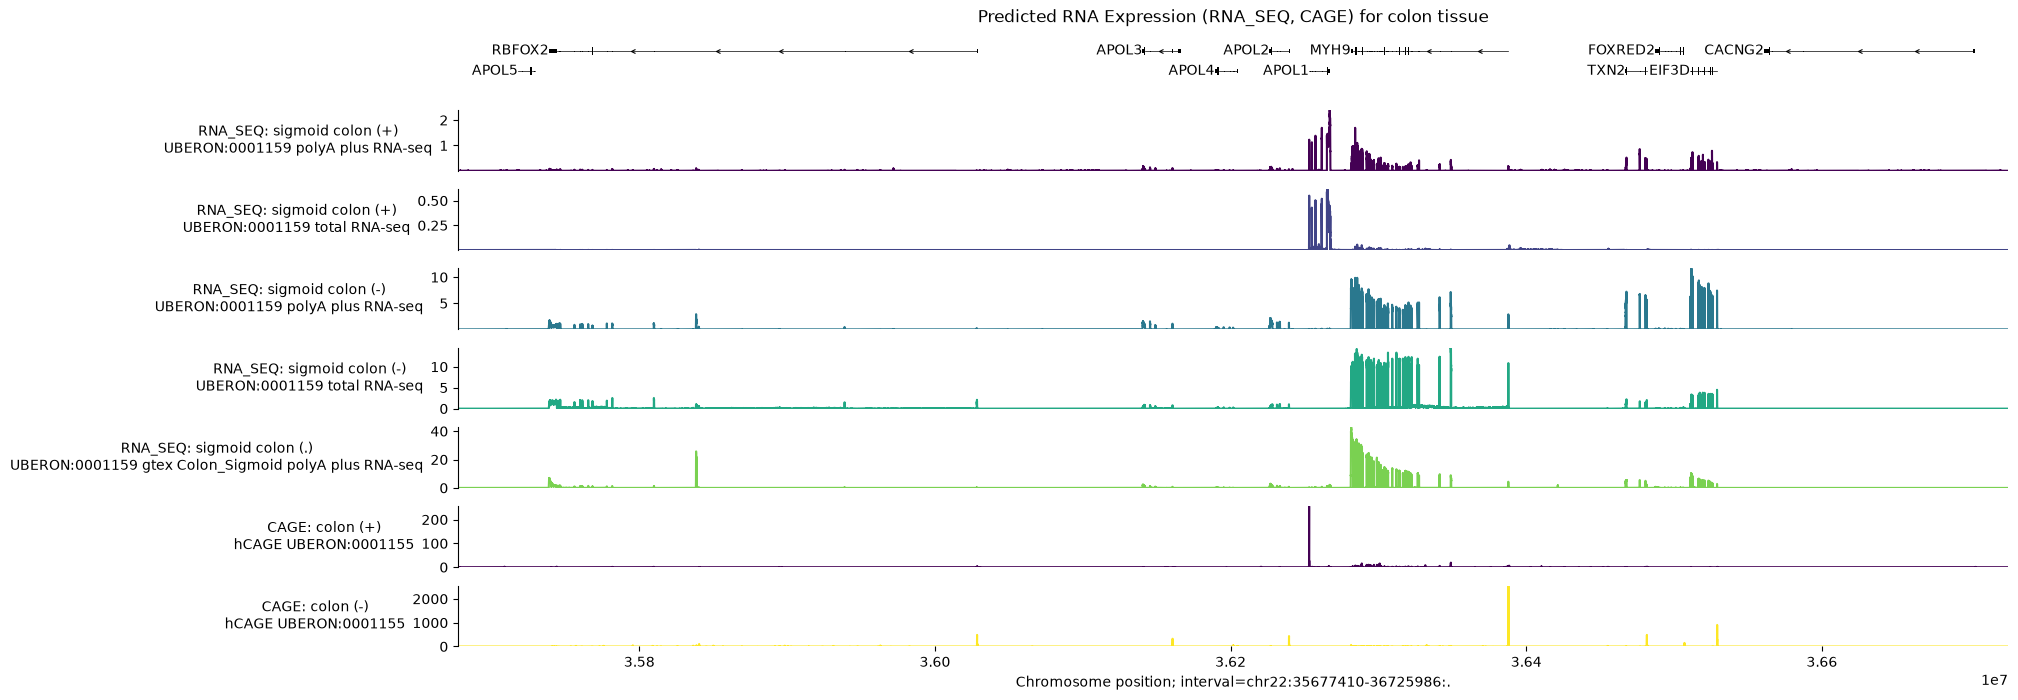

In [7]:
# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output.rna_seq,
            ylabel_template='RNA_SEQ: {biosample_name} ({strand})\n{name}',
        ),
        plot_components.Tracks(
            tdata=output.cage,
            ylabel_template='CAGE: {biosample_name} ({strand})\n{name}',
        ),
    ],
    interval=interval,
    title='Predicted RNA Expression (RNA_SEQ, CAGE) for colon tissue',
)

In [8]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

In [9]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.interpretation import ism
from alphagenome.models import dna_client
from alphagenome.models import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd

In [10]:
API_KEY = "***REMOVED***"

dna_model = dna_client.create(API_KEY)

In [11]:
[output.name for output in dna_client.OutputType]

['ATAC',
 'CAGE',
 'DNASE',
 'RNA_SEQ',
 'CHIP_HISTONE',
 'CHIP_TF',
 'SPLICE_SITES',
 'SPLICE_SITE_USAGE',
 'SPLICE_JUNCTIONS',
 'CONTACT_MAPS',
 'PROCAP']

In [12]:
output = dna_model.predict_sequence(
    sequence='GATTACA'.center(
        dna_client.SEQUENCE_LENGTH_1MB, 'N'
    ), # Pad to valid sequence length.
    requested_outputs=[dna_client.OutputType.DNASE],
    ontology_terms=['UBERON:0002048'], # Lung
)

In [13]:
dnase = output.dnase
type(dnase)

alphagenome.data.track_data.TrackData

In [14]:
print(dnase.values.shape)

dnase.values

(1048576, 1)


array([[0.00187683],
       [0.00172424],
       [0.00177765],
       ...,
       [0.0019989 ],
       [0.00292969],
       [0.0039978 ]], shape=(1048576, 1), dtype=float32)

In [15]:
dnase.metadata

,name,strand,Assay title,ontology_curie,biosample_name,biosample_type,biosample_life_stage,data_source,endedness,genetically_modified,nonzero_mean
0,UBERON:0002048 DNase-seq,.,DNase-seq,UBERON:0002048,lung,tissue,embryonic,encode,paired,False,0.427505


In [16]:
output = dna_model.predict_sequence(
    sequence='GATTAC'.center(
        dna_client.SEQUENCE_LENGTH_1MB, 'N'
    ), # Pad to valid sequence length
    requested_outputs=[
        dna_client.OutputType.CAGE,
        dna_client.OutputType.DNASE,
    ],
    ontology_terms=[
        'UBERON:0002048', # Lung.
        'UBERON:0000955', # Brain.
    ]
)

print(f'DNASE predictions shape: {output.dnase.values.shape}')
print(f'CAGE predictions shape: {output.cage.values.shape}')

DNASE predictions shape: (1048576, 2)
CAGE predictions shape: (1048576, 4)


In [17]:
output.cage.metadata

,name,strand,Assay title,ontology_curie,biosample_name,biosample_type,data_source,nonzero_mean
0,hCAGE UBERON:0000955,+,hCAGE,UBERON:0000955,brain,tissue,fantom,28.432245
1,hCAGE UBERON:0002048,+,hCAGE,UBERON:0002048,lung,tissue,fantom,30.655853
2,hCAGE UBERON:0000955,-,hCAGE,UBERON:0000955,brain,tissue,fantom,28.432245
3,hCAGE UBERON:0002048,-,hCAGE,UBERON:0002048,lung,tissue,fantom,30.655853


In [18]:
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
gtf_transcripts = gene_annotation.filter_to_mane_select_transcript(gtf_transcripts)
transcript_extractor = transcript_utils.TranscriptExtractor(gtf_transcripts)

In [19]:
interval = gene_annotation.get_gene_interval(gtf, gene_symbol='CYP2B6')
interval

Interval(chromosome='chr19', start=40991281, end=41018398, strand='+', name='CYP2B6')

In [20]:
interval = interval.resize(dna_client.SEQUENCE_LENGTH_1MB)

In [21]:
interval.width

1048576

In [22]:
dna_client.SUPPORTED_SEQUENCE_LENGTHS.keys()

dict_keys(['SEQUENCE_LENGTH_16KB', 'SEQUENCE_LENGTH_100KB', 'SEQUENCE_LENGTH_500KB', 'SEQUENCE_LENGTH_1MB'])

In [23]:
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs=[dna_client.OutputType.RNA_SEQ],
    ontology_terms=['UBERON:0001114'],
)  # Right liver lobe.

output.rna_seq.values.shape

(1048576, 3)

In [24]:
transcripts = transcript_extractor.extract(interval)
print(f'Extracted {len(transcripts)} transcripts in this interval.')

Extracted 28 transcripts in this interval.


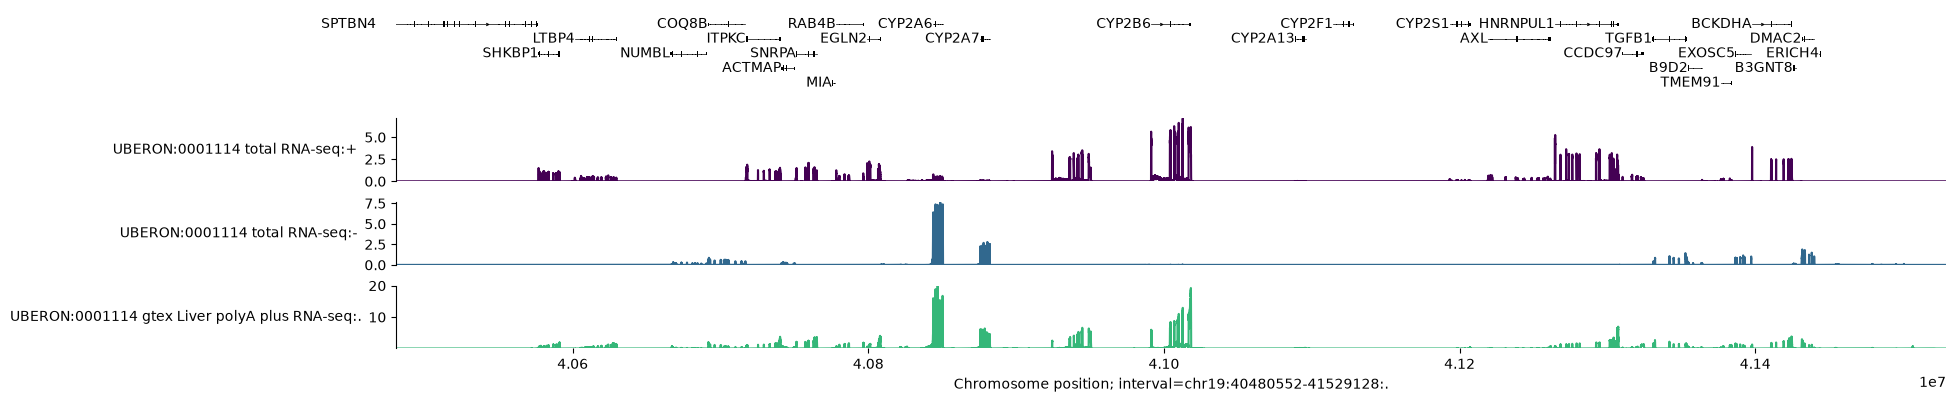

In [25]:
plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.Tracks(output.rna_seq),
    ],
    interval=output.rna_seq.interval,
)

plt.show()

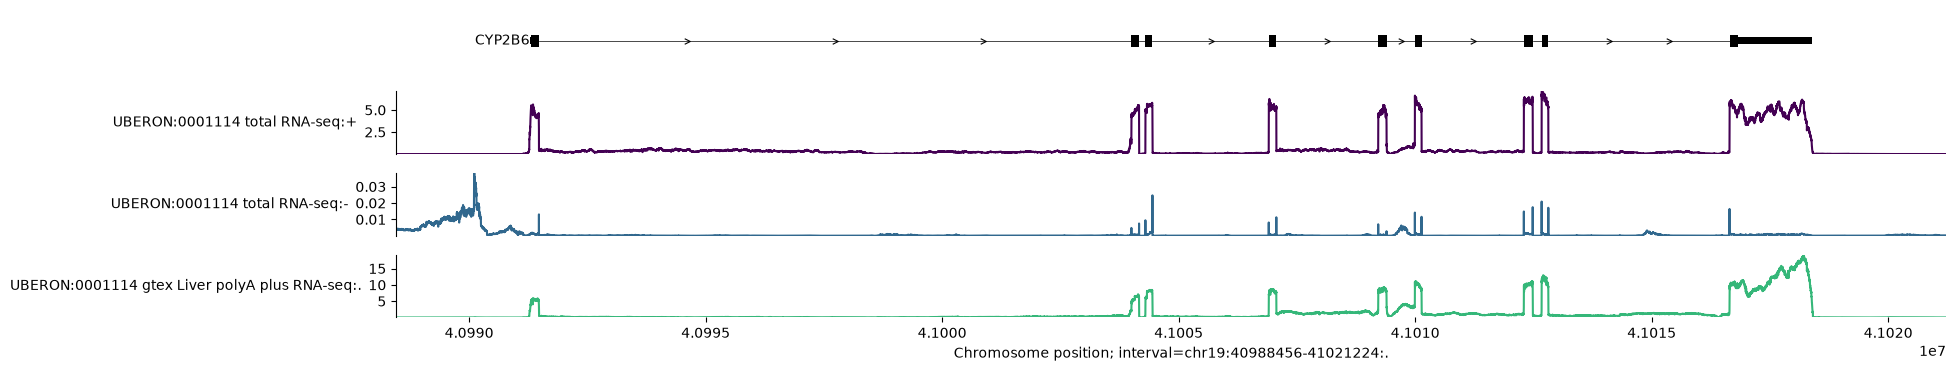

In [26]:
plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(
            transcripts, fig_height=0.1
        ),
        plot_components.Tracks(output.rna_seq),
    ],
    interval=output.rna_seq.interval.resize(2**15),
)

plt.show()

In [27]:
variant = genome.Variant(
    chromosome='chr22',
    position=36201698,
    reference_bases='A',  # Can differ from the true reference genome base.
    alternate_bases='C',
)

In [28]:
interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
interval

Interval(chromosome='chr22', start=35677410, end=36725986, strand='.', name='')

In [29]:
variant_output = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[dna_client.OutputType.RNA_SEQ],
    ontology_terms=['UBERON:0001157'],
) # Colon - Transverse.

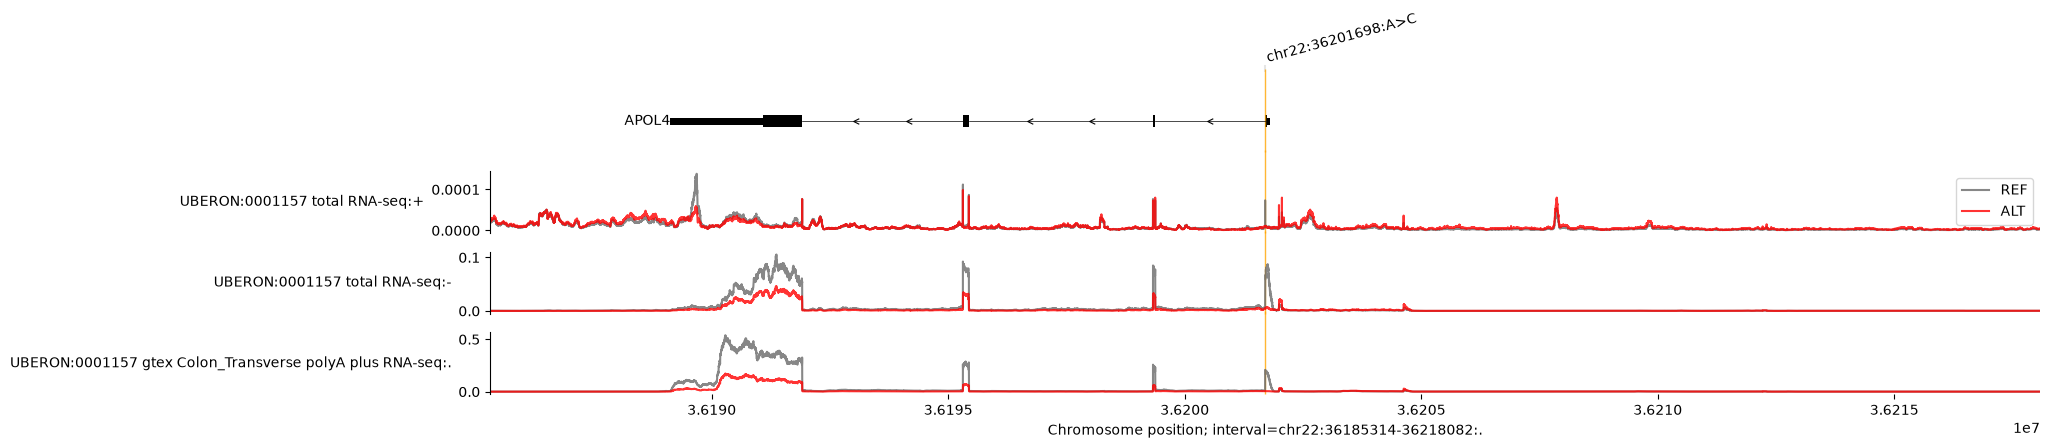

In [30]:
transcripts = transcript_extractor.extract(interval)

plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.OverlaidTracks(
            tdata={
                'REF': variant_output.reference.rna_seq,
                'ALT': variant_output.alternate.rna_seq,
            },
            colors={'REF': 'dimgrey', 'ALT': 'red'},
        ),
    ],
    interval=variant_output.reference.rna_seq.interval.resize(2**15),
    # Annotate the location of the variant as a vertical line.
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
plt.show()

In [31]:
variant_scorer = variant_scorers.RECOMMENDED_VARIANT_SCORERS['RNA_SEQ']

variant_scores = dna_model.score_variant(
    interval=interval, variant=variant, variant_scorers=[variant_scorer]
)

In [32]:
variant_scores = variant_scores[0]
variant_scores

AnnData object with n_obs × n_vars = 37 × 371
    obs: 'gene_id', 'strand', 'gene_name', 'gene_type'
    var: 'name', 'strand', 'Assay title', 'ontology_curie', 'biosample_name', 'biosample_type', 'biosample_life_stage', 'gtex_tissue', 'data_source', 'endedness', 'genetically_modified', 'nonzero_mean'
    uns: 'interval', 'variant', 'variant_scorer'
    layers: 'quantiles', None (.X)

In [33]:
variant_scores.X.shape

(37, 371)

In [34]:
variant_scores.obs.head()

,gene_id,strand,gene_name,gene_type
0,ENSG00000100320.24,-,RBFOX2,protein_coding
1,ENSG00000100336.18,-,APOL4,protein_coding
2,ENSG00000100342.22,+,APOL1,protein_coding
3,ENSG00000100345.23,-,MYH9,protein_coding
4,ENSG00000100348.10,-,TXN2,protein_coding


In [35]:
variant_scores.var

,name,strand,Assay title,ontology_curie,biosample_name,biosample_type,biosample_life_stage,gtex_tissue,data_source,endedness,genetically_modified,nonzero_mean
0,CL:0000047 polyA plus RNA-seq,.,polyA plus RNA-seq,CL:0000047,neuronal stem cell,in_vitro_differentiated_cells,embryonic,,encode,paired,False,0.143617
1,CL:0000062 total RNA-seq,.,total RNA-seq,CL:0000062,osteoblast,primary_cell,adult,,encode,paired,False,0.094144
2,CL:0000084 polyA plus RNA-seq,.,polyA plus RNA-seq,CL:0000084,T-cell,primary_cell,adult,,encode,paired,False,0.124296
3,CL:0000084 total RNA-seq,.,total RNA-seq,CL:0000084,T-cell,primary_cell,adult,,encode,single,False,0.100934
4,CL:0000115 total RNA-seq,.,total RNA-seq,CL:0000115,endothelial cell,in_vitro_differentiated_cells,adult,,encode,single,False,0.135553
...,...,...,...,...,...,...,...,...,...,...,...,...
366,UBERON:0018115 polyA plus RNA-seq,.,polyA plus RNA-seq,UBERON:0018115,left renal pelvis,tissue,embryonic,,encode,single,False,0.268222
367,UBERON:0018116 polyA plus RNA-seq,.,polyA plus RNA-seq,UBERON:0018116,right renal pelvis,tissue,embryonic,,encode,single,False,0.258522
368,UBERON:0018117 polyA plus RNA-seq,.,polyA plus RNA-seq,UBERON:0018117,left renal cortex interstitium,tissue,embryonic,,encode,single,False,0.215190
369,UBERON:0018118 polyA plus RNA-seq,.,polyA plus RNA-seq,UBERON:0018118,right renal cortex interstitium,tissue,embryonic,,encode,single,False,0.365676


In [36]:
print(f'Interval: {variant_scores.uns["interval"]}')
print(f'Variant: {variant_scores.uns["variant"]}')
print(f'Variant scorer: {variant_scores.uns["variant_scorer"]}')

Interval: chr22:35677410-36725986:.
Variant: chr22:36201698:A>C
Variant scorer: GeneMaskLFCScorer(requested_output=RNA_SEQ)


In [37]:
variant_scorers.tidy_scores([variant_scores], match_gene_strand=True)

,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,...,ontology_curie,biosample_name,biosample_type,biosample_life_stage,gtex_tissue,data_source,endedness,genetically_modified,raw_score,quantile_score
0,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100320,RBFOX2,protein_coding,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000047,neuronal stem cell,in_vitro_differentiated_cells,embryonic,,encode,paired,False,0.000420,0.494571
1,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100320,RBFOX2,protein_coding,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000062,osteoblast,primary_cell,adult,,encode,paired,False,-0.000993,-0.731397
2,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100320,RBFOX2,protein_coding,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000084,T-cell,primary_cell,adult,,encode,paired,False,-0.002651,-0.893685
3,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100320,RBFOX2,protein_coding,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000084,T-cell,primary_cell,adult,,encode,single,False,-0.002788,-0.909503
4,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100320,RBFOX2,protein_coding,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000115,endothelial cell,in_vitro_differentiated_cells,adult,,encode,single,False,0.000354,0.441693
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13722,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000293594,ENSG00000293594,processed_pseudogene,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,UBERON:0018115,left renal pelvis,tissue,embryonic,,encode,single,False,-0.007697,-0.993277
13723,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000293594,ENSG00000293594,processed_pseudogene,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,UBERON:0018116,right renal pelvis,tissue,embryonic,,encode,single,False,-0.007846,-0.993277
13724,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000293594,ENSG00000293594,processed_pseudogene,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,UBERON:0018117,left renal cortex interstitium,tissue,embryonic,,encode,single,False,-0.005295,-0.977415
13725,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000293594,ENSG00000293594,processed_pseudogene,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,UBERON:0018118,right renal cortex interstitium,tissue,embryonic,,encode,single,False,-0.006396,-0.985885


In [38]:
# 16KB DNA sequence to use as context when making predictions.
sequence_interval = genome.Interval('chr20', 3_753_000, 3_753_400)
sequence_interval = sequence_interval.resize(dna_client.SEQUENCE_LENGTH_16KB)

# Mutate all bases in the central 256-base region of the sequence_interval.
ism_interval = sequence_interval.resize(256)

In [39]:
dnase_variant_scorer = variant_scorers.CenterMaskScorer(
    requested_output=dna_client.OutputType.DNASE,
    width=501,
    aggregation_type=variant_scorers.AggregationType.DIFF_MEAN,
)

In [40]:
variant_scores = dna_model.score_ism_variants(
    interval=sequence_interval,
    ism_interval=ism_interval,
    variant_scorers=[dnase_variant_scorer],
)

  0%|          | 0/26 [00:00<?, ?it/s]

In [41]:
len(variant_scores)

768

In [42]:
# Index into first variant and first scorer.
variant_scores[0][0].X.shape

(1, 305)

In [43]:
def extract_k562(adata):
  values = adata.X[:, adata.var['ontology_curie'] == 'EFO:0002067']
  assert values.size == 1
  return values.flatten()[0]


ism_result = ism.ism_matrix(
    [extract_k562(x[0]) for x in variant_scores],
    variants=[v[0].uns['variant'] for v in variant_scores],
)

In [44]:
ism_result.shape

(256, 4)

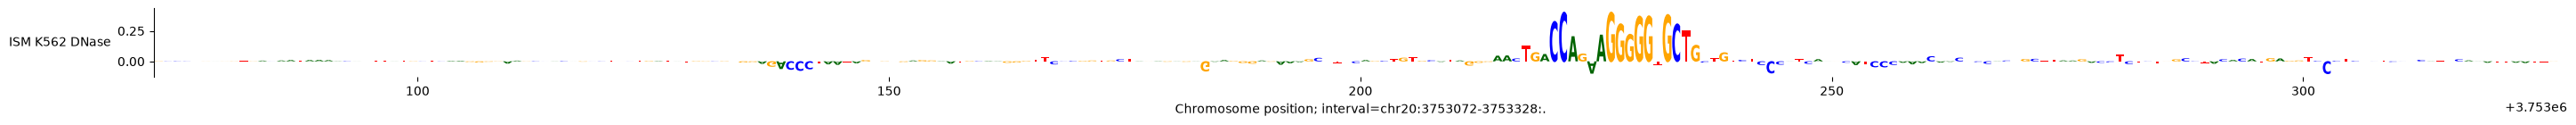

In [45]:
plot_components.plot(
    [
        plot_components.SeqLogo(
            scores=ism_result,
            scores_interval=ism_interval,
            ylabel='ISM K562 DNase',
        )
    ],
    interval=ism_interval,
    fig_width=35,
)

plt.show()

# Visualizing predictions

In [46]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation, genome, track_data, transcript
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [47]:
API_KEY = "***REMOVED***"

dna_model = dna_client.create(API_KEY)

In [48]:
# Load metadata objects for human.
output_metadata = dna_model.output_metadata(
    organism=dna_client.Organism.HOMO_SAPIENS
)

In [49]:
# Load gene annotations (from GENCODE).
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Filter to protein-coding genes and highly supported transcripts.
gtf_transcript = gene_annotation.filter_transcript_support_level(
    gene_annotation.filter_protein_coding(gtf), ['1']
)

# Extractor for identifying transcripts in a region.
transcript_extractor = transcript.TranscriptExtractor(gtf_transcript)

# Also define an extractor that fetches only the longest transcript per gene.
gtf_longest_transcript = gene_annotation.filter_to_longest_transcript(
    gtf_transcript
)
longest_transcript_extractor = transcript.TranscriptExtractor(
    gtf_longest_transcript
)

In [50]:
# Define interval to make predictions for (used throughout this tutorial).
# Note that the interval width must be one of the supported sequence lengths.
interval = genome.Interval('chr22', 36_150_498, 36_252_898).resize(
    dna_client.SEQUENCE_LENGTH_1MB
)

# Define the tissues/cell-types to predict expression for.
ontology_terms = [
    'UBERON:0001159',  # Colon - Sigmoid.
    'UBERON:0001155',  # Colon - Transverse.
]

# Make predictions.
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.CAGE,
    },
    ontology_terms=ontology_terms,
)

# Extract the longest transcripts per gene for this interval.
longest_transcripts = longest_transcript_extractor.extract(interval)

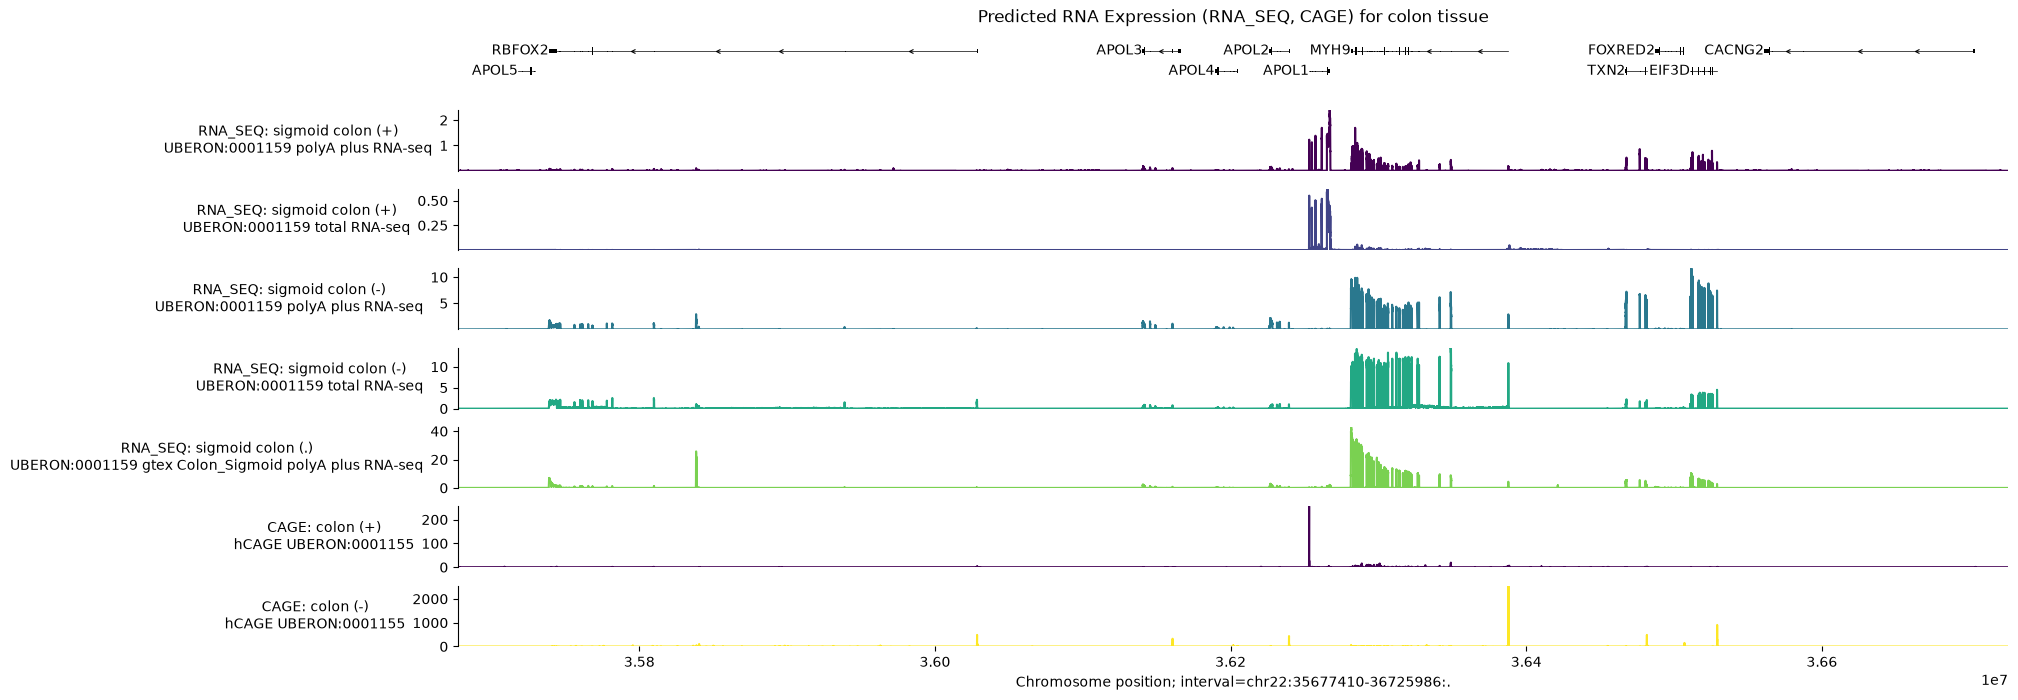

In [51]:
# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output.rna_seq,
            ylabel_template='RNA_SEQ: {biosample_name} ({strand})\n{name}',
        ),
        plot_components.Tracks(
            tdata=output.cage,
            ylabel_template='CAGE: {biosample_name} ({strand})\n{name}',
        ),
    ],
    interval=interval,
    title='Predicted RNA Expression (RNA_SEQ, CAGE) for colon tissue',
)

In [52]:
[t.info['gene_name'] for t in longest_transcripts if t.strand == '+']

['APOL5', 'APOL1']

In [53]:
# Define the variant of interest.
variant_string = 'chr22:36201698:A>C'
variant = genome.Variant.from_str(variant_string)
variant

Variant(chromosome='chr22', position=36201698, reference_bases='A', alternate_bases='C', name='')

In [54]:
# Make predictions for sequences containing the REF and ALT alleles.
output = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs={
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.CAGE,
    },
    ontology_terms=ontology_terms,
)

In [55]:
# Zoom in on the region around APOL4.
apol4_interval = gene_annotation.get_gene_interval(gtf, gene_symbol='APOL4')

# Add 1KB on either side of the gene body.
apol4_interval.resize_inplace(apol4_interval.width + 1000)

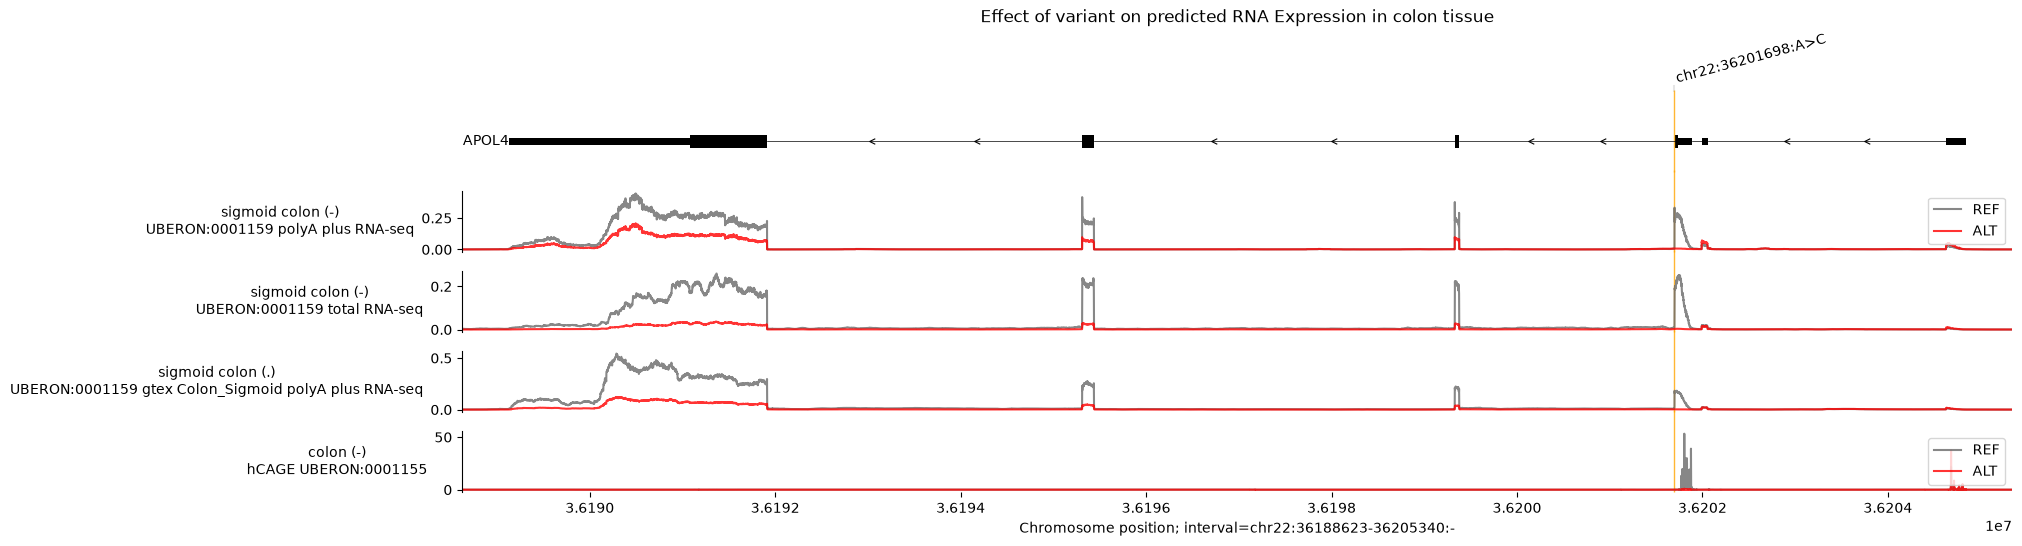

In [56]:
# Define the colors for REF and ALT predictions.
ref_alt_colors = {'REF': 'dimgrey', 'ALT': 'red'}

# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        # RNA-seq tracks.
        plot_components.OverlaidTracks(
            tdata={
                'REF': output.reference.rna_seq.filter_to_nonpositive_strand(),
                'ALT': output.alternate.rna_seq.filter_to_nonpositive_strand(),
            },
            colors=ref_alt_colors,
            ylabel_template='{biosample_name} ({strand})\n{name}',
        ),
        # CAGE track.
        plot_components.OverlaidTracks(
            tdata={
                'REF': output.reference.cage.filter_to_nonpositive_strand(),
                'ALT': output.alternate.cage.filter_to_nonpositive_strand(),
            },
            colors=ref_alt_colors,
            ylabel_template='{biosample_name} ({strand})\n{name}',
        ),
    ],
    annotations=[plot_components.VariantAnnotation([variant])],
    interval=apol4_interval,
    title='Effect of variant on predicted RNA Expression in colon tissue',
)

In [57]:
# Run predictions with an additional ontology to highlight differences across
# tissues.
ontology_terms = [
    'UBERON:0001159',  # Colon - Sigmoid.
    'UBERON:0002048',  # lung.
]

# Make predictions.
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={
        dna_client.OutputType.RNA_SEQ,
    },
    ontology_terms=ontology_terms,
)

In [58]:
# Define pA sites in hg38 coordinates.
apol4_pAs = [genome.Interval('chr22', 36_189_128, 36_189_129, '-'),
             genome.Interval('chr22', 36_190_089, 36_190_090, '-'),
             genome.Interval('chr22', 36_190_144, 36_190_145, '-')]

# Define plotting interval as first/last pA plus some offset distance.

offset = 200
pA_interval = genome.Interval('chr22',
                              36_189_128 - offset,
                              36_190_145 + offset,
                              '-')

# Define intervals annotation.
pA_labels = ['pA_3', 'pA_2', 'pA_1']

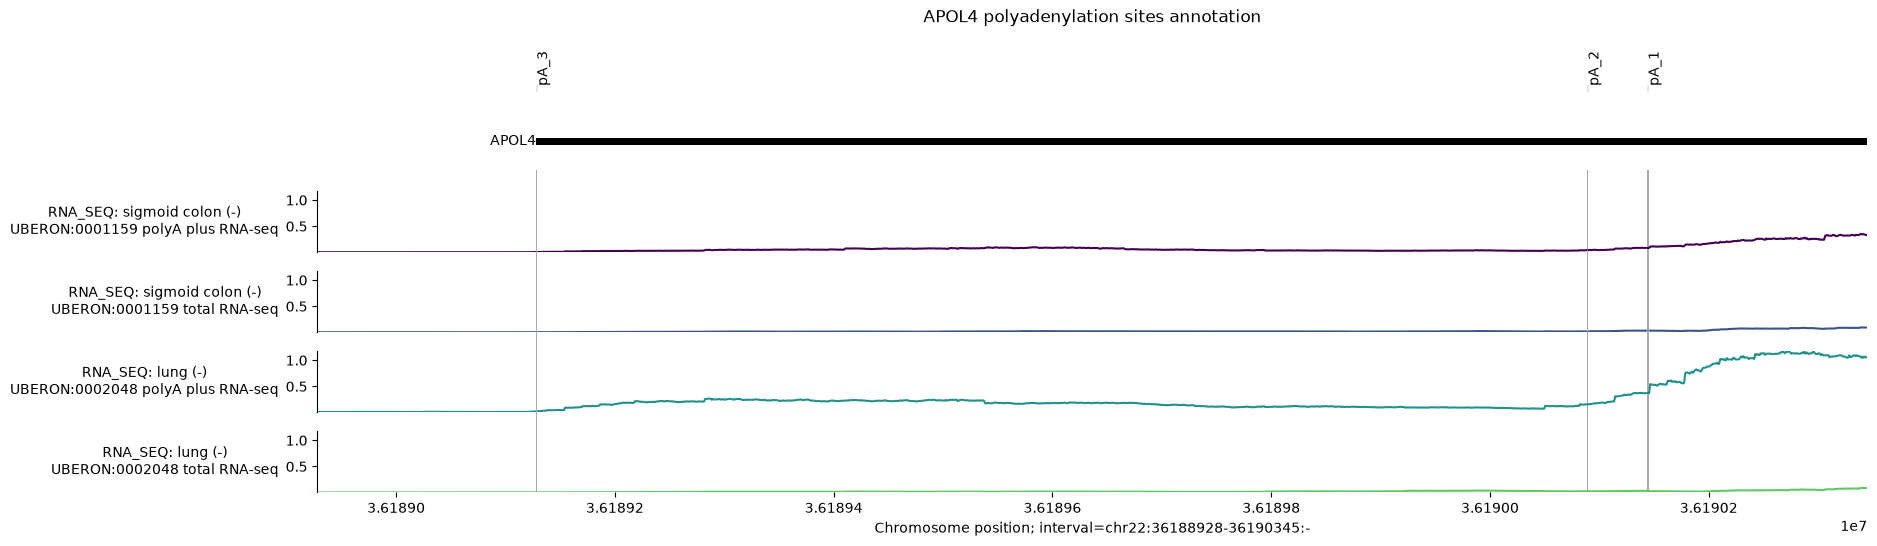

In [59]:
# Build plot.
# NOTE: Depending on annotation distance and interval zoom some annotations may # appear as overlapping.

plot = plot_components.plot(
    [plot_components.TranscriptAnnotation(longest_transcripts),
        # RNA-seq tracks.
        plot_components.Tracks(
            tdata = output.rna_seq.filter_to_negative_strand(),
            ylabel_template = 'RNA_SEQ: {biosample_name} ({strand})\n{name}',
            shared_y_scale = True,
            )
    ],
    annotations=[
        plot_components.IntervalAnnotation(apol4_pAs,
                                           alpha = 1,
                                           labels = pA_labels,
                                           label_angle = 90)],
    interval = pA_interval,
    title='APOL4 polyadenylation sites annotation',

)

In [60]:
# List of IDs corresponding to various intestinal tissues.
ontology_terms = [
    'UBERON:0000317',
    'UBERON:0001155',
    'UBERON:0001157',
    'UBERON:0001159',
    'UBERON:0004992',
    'UBERON:0008971',
]

In [61]:
# Make predictions.
output = dna_model.predict_interval(
    interval,
    requested_outputs={
        dna_client.OutputType.DNASE,
        dna_client.OutputType.ATAC,
    },
    ontology_terms=ontology_terms,
)

In [62]:
# Two putative promoter intervals from Ensembl.
promoter_intervals = [
    genome.Interval(
        'chr22', 36_201_799, 36_202_681, name='Ensembl_promoter:ENSR00001367790'
    ),
    genome.Interval(
        'chr22', 36_204_705, 36_205_330, name='Ensembl_promoter:ENSR00001367792'
    ),
]

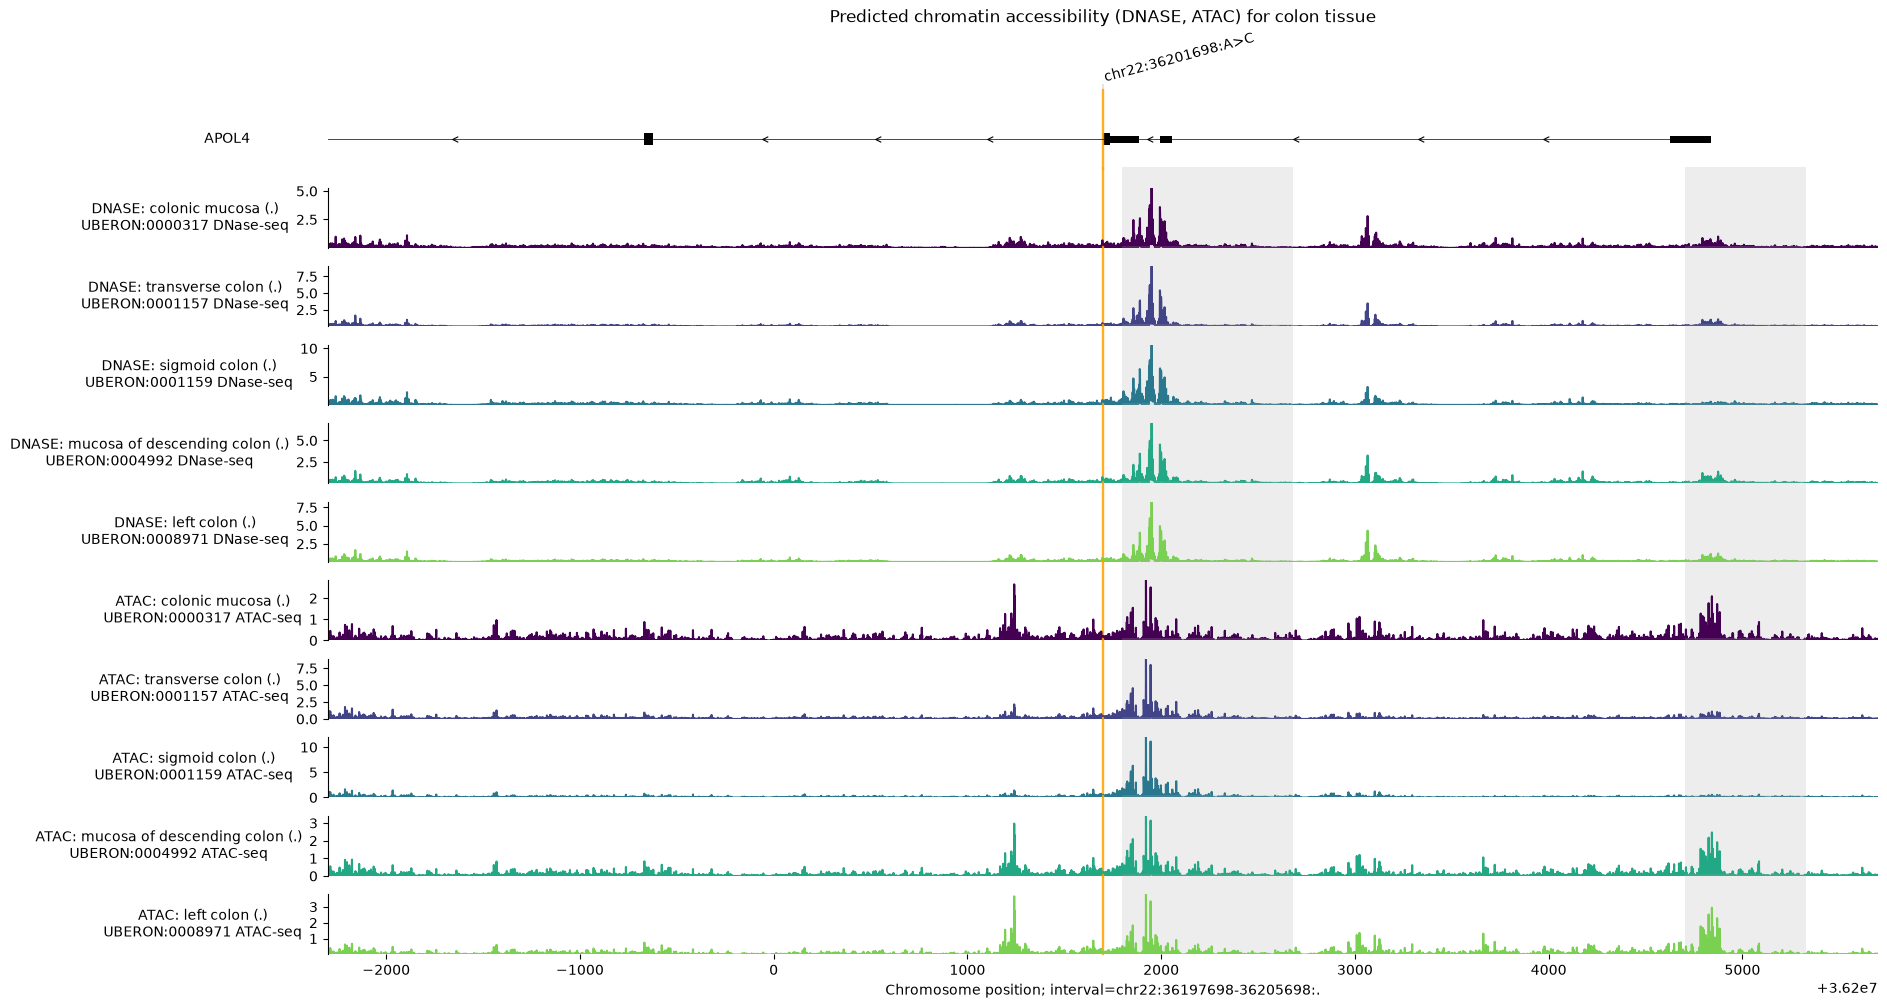

In [63]:
# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output.dnase,
            ylabel_template='DNASE: {biosample_name} ({strand})\n{name}',
        ),
        plot_components.Tracks(
            tdata=output.atac,
            ylabel_template='ATAC: {biosample_name} ({strand})\n{name}',
        ),
    ],
    # Plot an 8kb window around the variant.
    interval=variant.reference_interval.resize(8000),
    annotations=[
        plot_components.VariantAnnotation([variant]),
        plot_components.IntervalAnnotation(promoter_intervals),
    ],
    title='Predicted chromatin accessibility (DNASE, ATAC) for colon tissue',
)

In [64]:
# List of IDs corresponding to various intestinal tissues.
ontology_terms = [
    'UBERON:0001157',
    'UBERON:0001159',
]

In [65]:
# Make predictions for splicing outputs and RNA_SEQ.
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.SPLICE_SITES,
        dna_client.OutputType.SPLICE_SITE_USAGE,
        dna_client.OutputType.SPLICE_JUNCTIONS,
    },
    ontology_terms=ontology_terms,
)

In [66]:
output.splice_sites.metadata

,name,strand
0,donor,+
1,acceptor,+
2,donor,-
3,acceptor,-


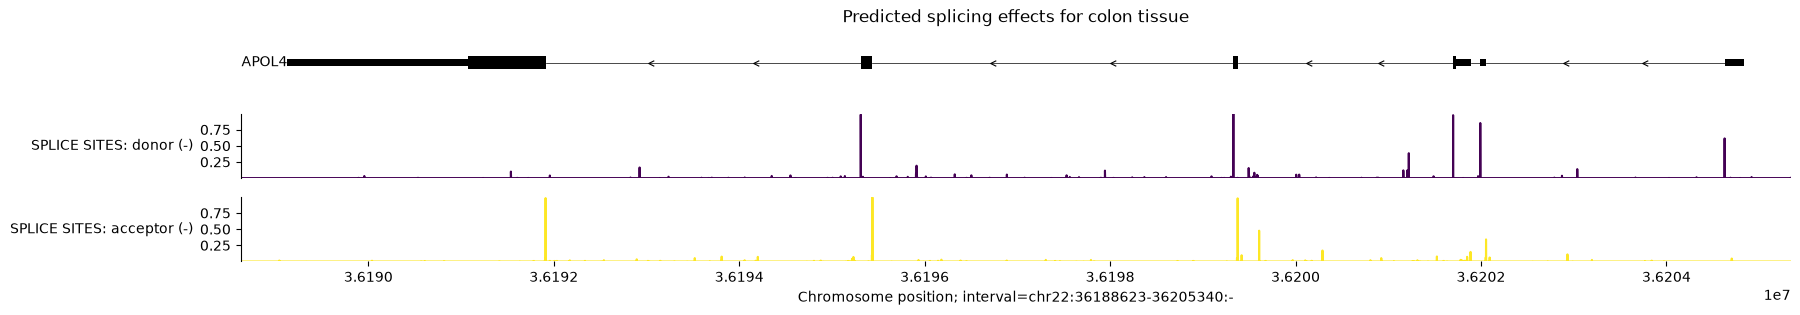

In [67]:
# Build plot.
# Since APOL4 is on the negative DNA strand, we use `filter_negative_strand` to
# consider only negative stranded splice predictions.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output.splice_sites.filter_to_negative_strand(),
            ylabel_template='SPLICE SITES: {name} ({strand})',
        ),
    ],
    interval=apol4_interval,
    title='Predicted splicing effects for colon tissue',
)

In [68]:
# Make predictions for REF and ALT alleles.
output = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs={
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.SPLICE_SITES,
        dna_client.OutputType.SPLICE_SITE_USAGE,
        dna_client.OutputType.SPLICE_JUNCTIONS,
    },
    ontology_terms=ontology_terms,
)

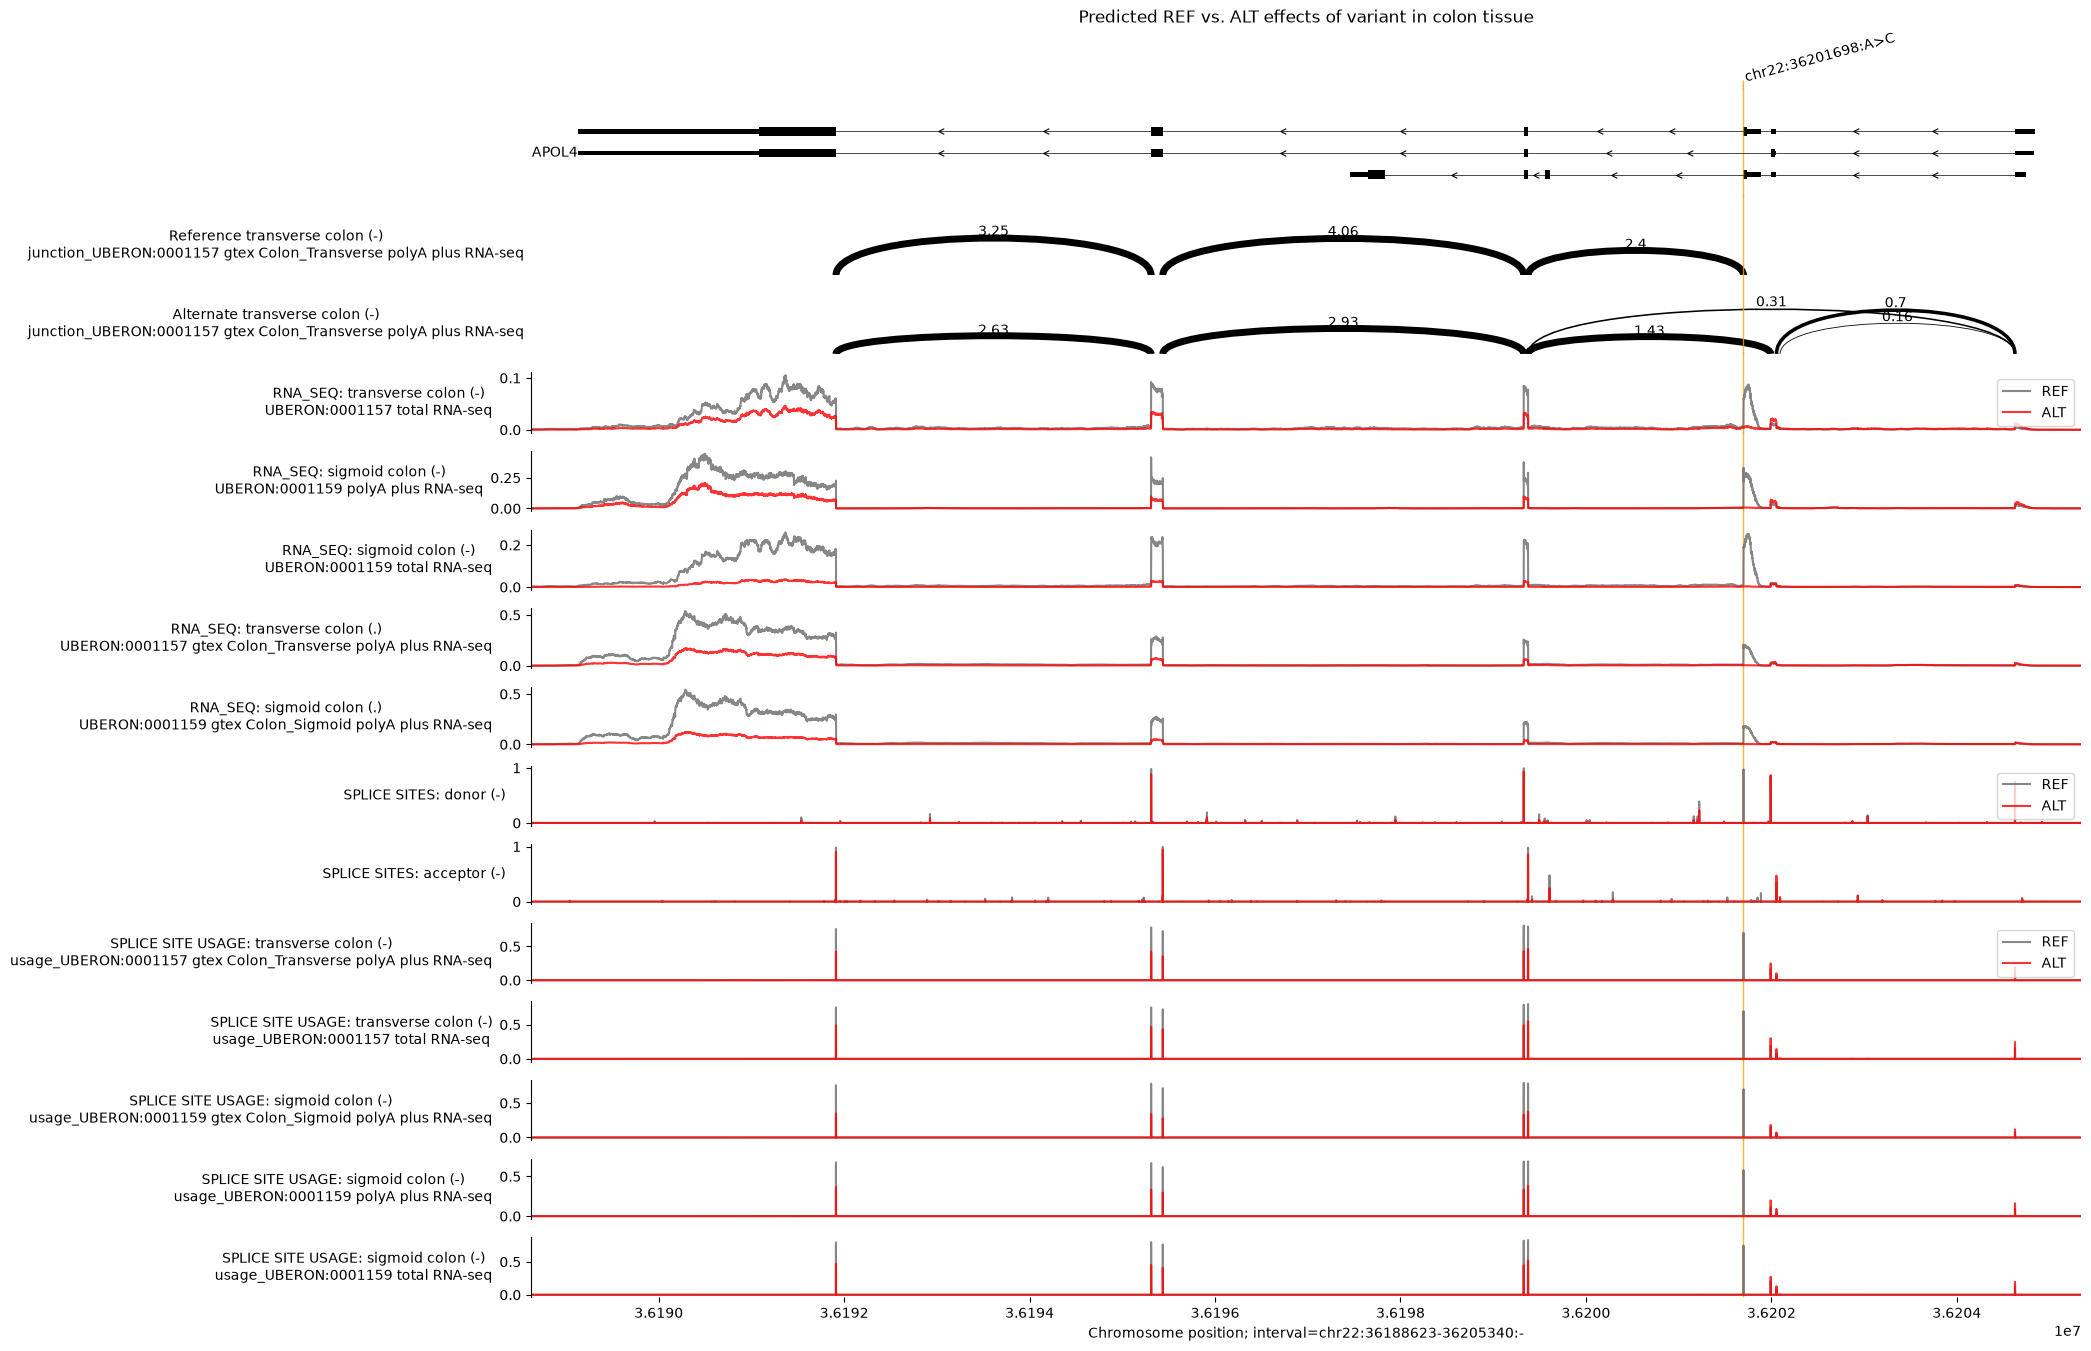

In [69]:
# Get all transcripts, not just the longest one per gene.
transcripts = transcript_extractor.extract(interval)

ref_output = output.reference
alt_output = output.alternate

# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.Sashimi(
            ref_output.splice_junctions
            .filter_to_strand('-')
            .filter_by_tissue('Colon_Transverse'),
            ylabel_template='Reference {biosample_name} ({strand})\n{name}',
        ),
        plot_components.Sashimi(
            alt_output.splice_junctions
            .filter_to_strand('-')
            .filter_by_tissue('Colon_Transverse'),
            ylabel_template='Alternate {biosample_name} ({strand})\n{name}',
        ),
        plot_components.OverlaidTracks(
            tdata={
                'REF': ref_output.rna_seq.filter_to_nonpositive_strand(),
                'ALT': alt_output.rna_seq.filter_to_nonpositive_strand(),
            },
            colors=ref_alt_colors,
            ylabel_template='RNA_SEQ: {biosample_name} ({strand})\n{name}',
        ),
        plot_components.OverlaidTracks(
            tdata={
                'REF': ref_output.splice_sites.filter_to_nonpositive_strand(),
                'ALT': alt_output.splice_sites.filter_to_nonpositive_strand(),
            },
            colors=ref_alt_colors,
            ylabel_template='SPLICE SITES: {name} ({strand})',
        ),
        plot_components.OverlaidTracks(
            tdata={
                'REF': (
                    ref_output.splice_site_usage.filter_to_nonpositive_strand()
                ),
                'ALT': (
                    alt_output.splice_site_usage.filter_to_nonpositive_strand()
                ),
            },
            colors=ref_alt_colors,
            ylabel_template=(
                'SPLICE SITE USAGE: {biosample_name} ({strand})\n{name}'
            ),
        ),
    ],
    interval=apol4_interval,
    annotations=[plot_components.VariantAnnotation([variant])],
    title='Predicted REF vs. ALT effects of variant in colon tissue',
)

In [70]:
output_metadata.chip_histone[
    output_metadata.chip_histone['biosample_name'].str.contains('colon')
]

,name,strand,Assay title,ontology_curie,biosample_name,biosample_type,biosample_life_stage,histone_mark,data_source,endedness,genetically_modified,nonzero_mean
769,UBERON:0000317 Histone ChIP-seq H3K27ac,.,Histone ChIP-seq,UBERON:0000317,colonic mucosa,tissue,adult,H3K27ac,encode,single,False,0.749292
770,UBERON:0000317 Histone ChIP-seq H3K27me3,.,Histone ChIP-seq,UBERON:0000317,colonic mucosa,tissue,adult,H3K27me3,encode,single,False,1.773918
771,UBERON:0000317 Histone ChIP-seq H3K36me3,.,Histone ChIP-seq,UBERON:0000317,colonic mucosa,tissue,adult,H3K36me3,encode,single,False,1.865919
772,UBERON:0000317 Histone ChIP-seq H3K4me1,.,Histone ChIP-seq,UBERON:0000317,colonic mucosa,tissue,adult,H3K4me1,encode,single,False,0.941760
773,UBERON:0000317 Histone ChIP-seq H3K4me3,.,Histone ChIP-seq,UBERON:0000317,colonic mucosa,tissue,adult,H3K4me3,encode,single,False,0.739352
774,UBERON:0000317 Histone ChIP-seq H3K9ac,.,Histone ChIP-seq,UBERON:0000317,colonic mucosa,tissue,adult,H3K9ac,encode,single,False,0.950228
835,UBERON:0001157 Histone ChIP-seq H3K27ac,.,Histone ChIP-seq,UBERON:0001157,transverse colon,tissue,adult,H3K27ac,encode,single,False,0.785410
836,UBERON:0001157 Histone ChIP-seq H3K27me3,.,Histone ChIP-seq,UBERON:0001157,transverse colon,tissue,adult,H3K27me3,encode,single,False,0.825184
837,UBERON:0001157 Histone ChIP-seq H3K36me3,.,Histone ChIP-seq,UBERON:0001157,transverse colon,tissue,adult,H3K36me3,encode,single,False,0.823532
838,UBERON:0001157 Histone ChIP-seq H3K4me1,.,Histone ChIP-seq,UBERON:0001157,transverse colon,tissue,adult,H3K4me1,encode,single,False,0.812938


In [71]:
# List of IDs corresponding to various colon tissues in `CHIP_HISTONE` output.
ontology_terms = [
    'UBERON:0000317',
    'UBERON:0001155',
    'UBERON:0001157',
    'UBERON:0001159',
]

# Make predictions.
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={dna_client.OutputType.CHIP_HISTONE},
    ontology_terms=ontology_terms,
)

In [72]:
gtf_tss = gene_annotation.extract_tss(gtf_longest_transcript)

tss_as_intervals = [
    genome.Interval(
        chromosome=row.Chromosome,
        start=row.Start,
        end=row.End + 1000,  # Add extra 1Kb so the TSSs are visible.
        name=row.gene_name,
    )
    for _, row in gtf_tss.iterrows()
]

In [73]:
reordered_chip_histone = output.chip_histone.select_tracks_by_index(
    output.chip_histone.metadata.sort_values('histone_mark').index
)

histone_to_color = {
    'H3K27AC': '#e41a1c',
    'H3K36ME3': '#ff7f00',
    'H3K4ME1': '#377eb8',
    'H3K4ME3': '#984ea3',
    'H3K9AC': '#4daf4a',
    'H3K27ME3': '#ffc0cb',
}

track_colors = (
    reordered_chip_histone.metadata['histone_mark']
    .map(lambda x: histone_to_color.get(x.upper(), '#000000'))
    .values
)

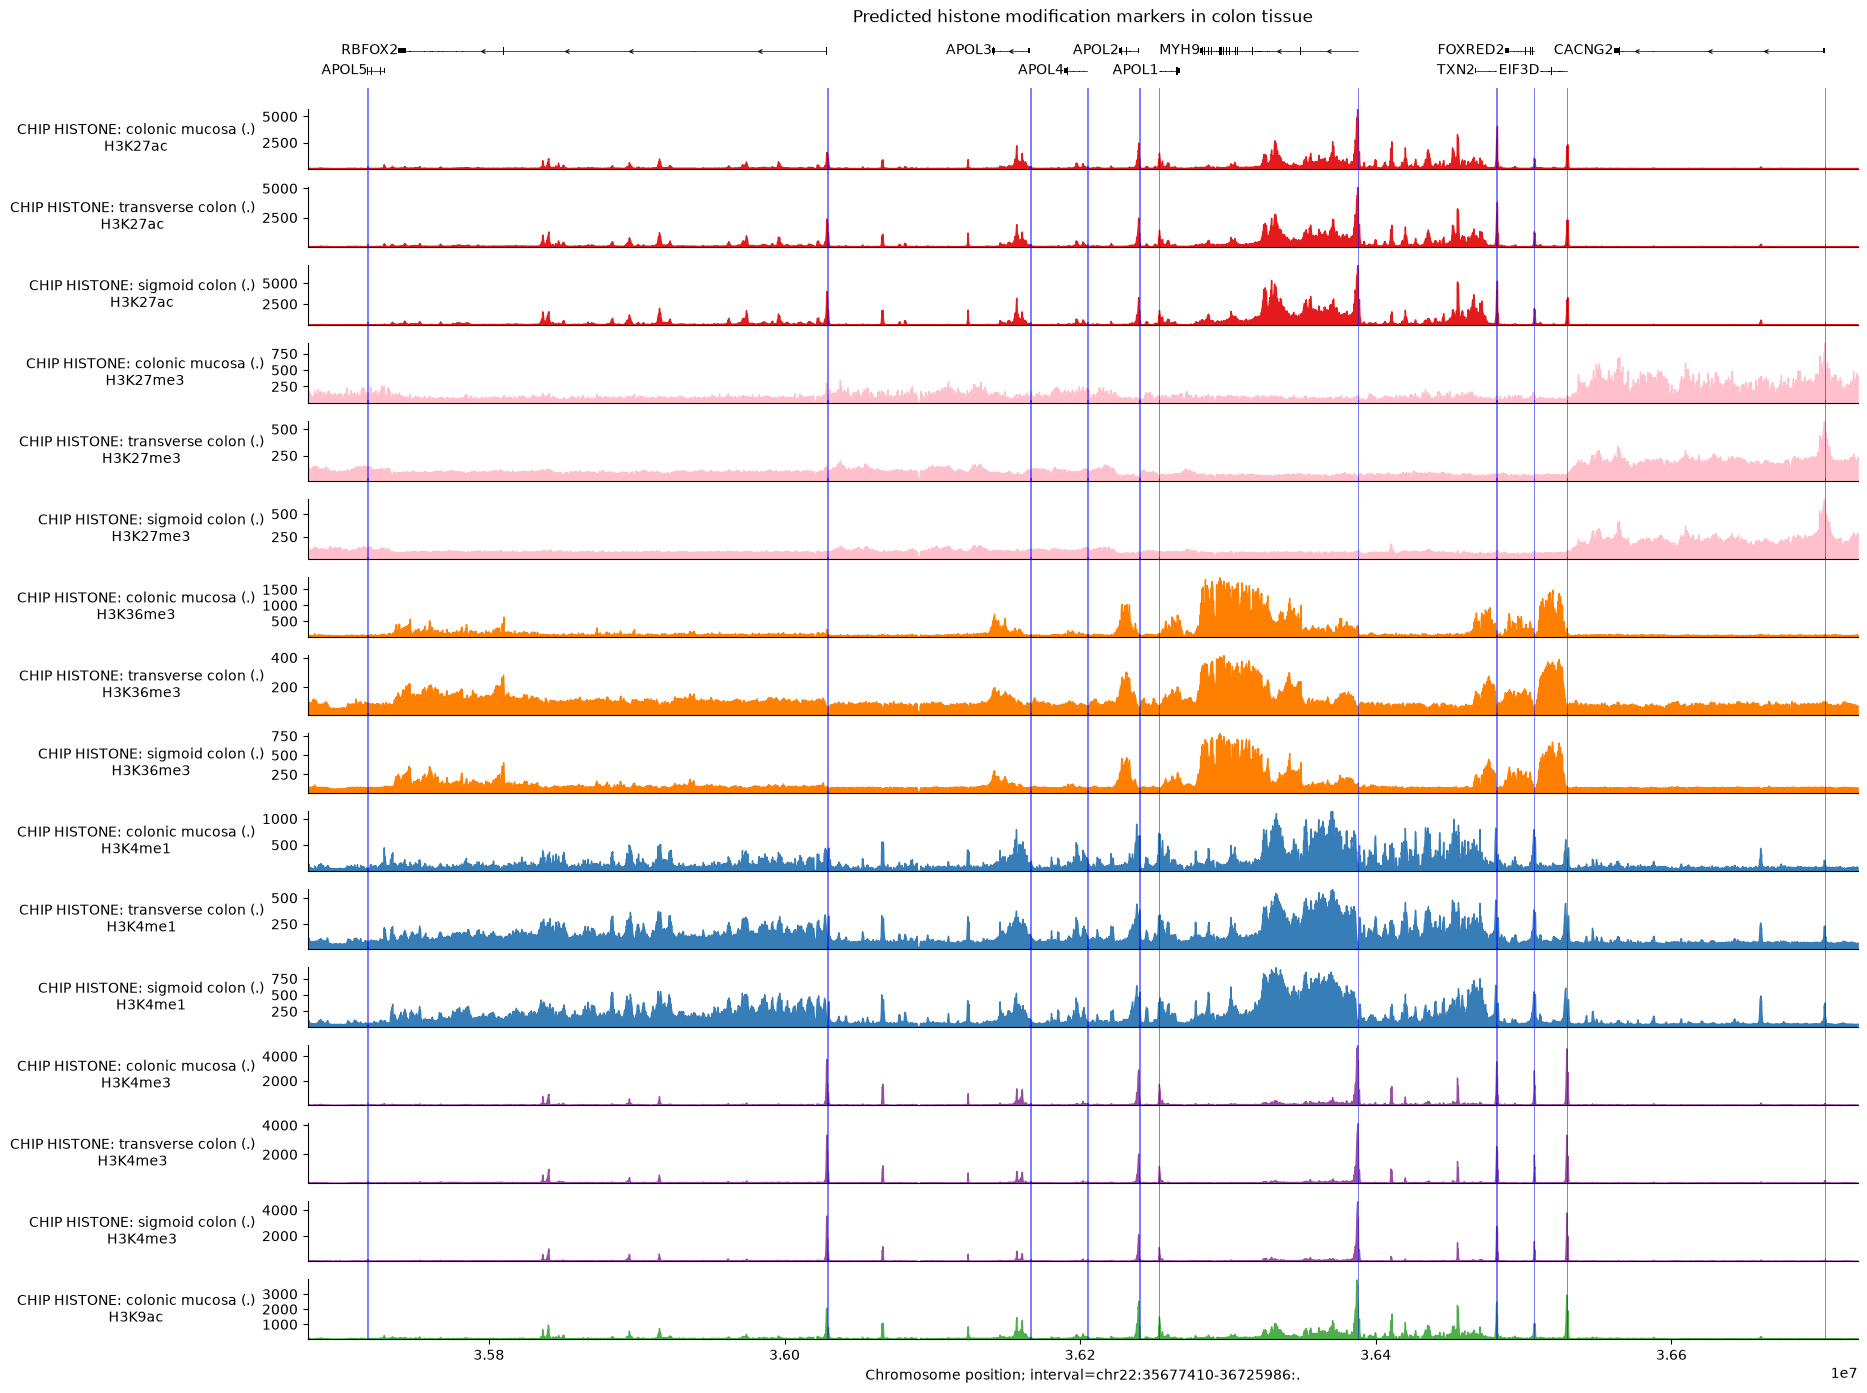

In [74]:
# Build plot.
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=reordered_chip_histone,
            ylabel_template=(
                'CHIP HISTONE: {biosample_name} ({strand})\n{histone_mark}'
            ),
            filled=True,
            track_colors=track_colors,
        ),
    ],
    interval=interval,
    annotations=[
        plot_components.IntervalAnnotation(
            tss_as_intervals, alpha=0.5, colors='blue'
        )
    ],
    despine_keep_bottom=True,
    title='Predicted histone modification markers in colon tissue',
)

In [75]:
ontology_terms = [
    'UBERON:0001159',  # Sigmoid colon.
    'UBERON:0001157',  # Transverse colon.
    'EFO:0002067',  # K562.
    'EFO:0001187',  # HepG2.
]

output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={dna_client.OutputType.CHIP_TF},
    ontology_terms=ontology_terms,
)

In [76]:
ontology_terms = [
    'EFO:0002067',  # K562.
    'EFO:0001187',  # HepG2.
]

output_chip_tf = output.chip_tf.filter_tracks(
    (output.chip_tf.metadata['ontology_curie'].isin(ontology_terms)).values
)
len(output_chip_tf.metadata)

845

In [77]:
max_predictions = output_chip_tf.metadata[
    ['ontology_curie', 'biosample_name', 'transcription_factor']
].copy()

max_predictions.loc[:, 'max_prediction'] = output_chip_tf.values.max(axis=0)
max_predictions.sort_values('max_prediction', ascending=False).reset_index(
    drop=True
)

,ontology_curie,biosample_name,transcription_factor,max_prediction
0,EFO:0002067,K562,POLR2G,20608.0
1,EFO:0002067,K562,PKNOX1,20224.0
2,EFO:0001187,HepG2,RBFOX2,19328.0
3,EFO:0002067,K562,GABPB1,18304.0
4,EFO:0001187,HepG2,REST,15488.0
...,...,...,...,...
840,EFO:0001187,HepG2,TCF12,183.0
841,EFO:0001187,HepG2,GPBP1L1,173.0
842,EFO:0002067,K562,ZNF778,159.0
843,EFO:0002067,K562,COPS2,149.0


In [78]:
print(f'Number of tracks before filtering: {len(output_chip_tf.metadata)}')

output_filtered = output_chip_tf.filter_tracks(
    output_chip_tf.values.max(axis=0) > 8000
)
print(f'Number of tracks after filtering: {len(output_filtered.metadata)}')

Number of tracks before filtering: 845
Number of tracks after filtering: 14


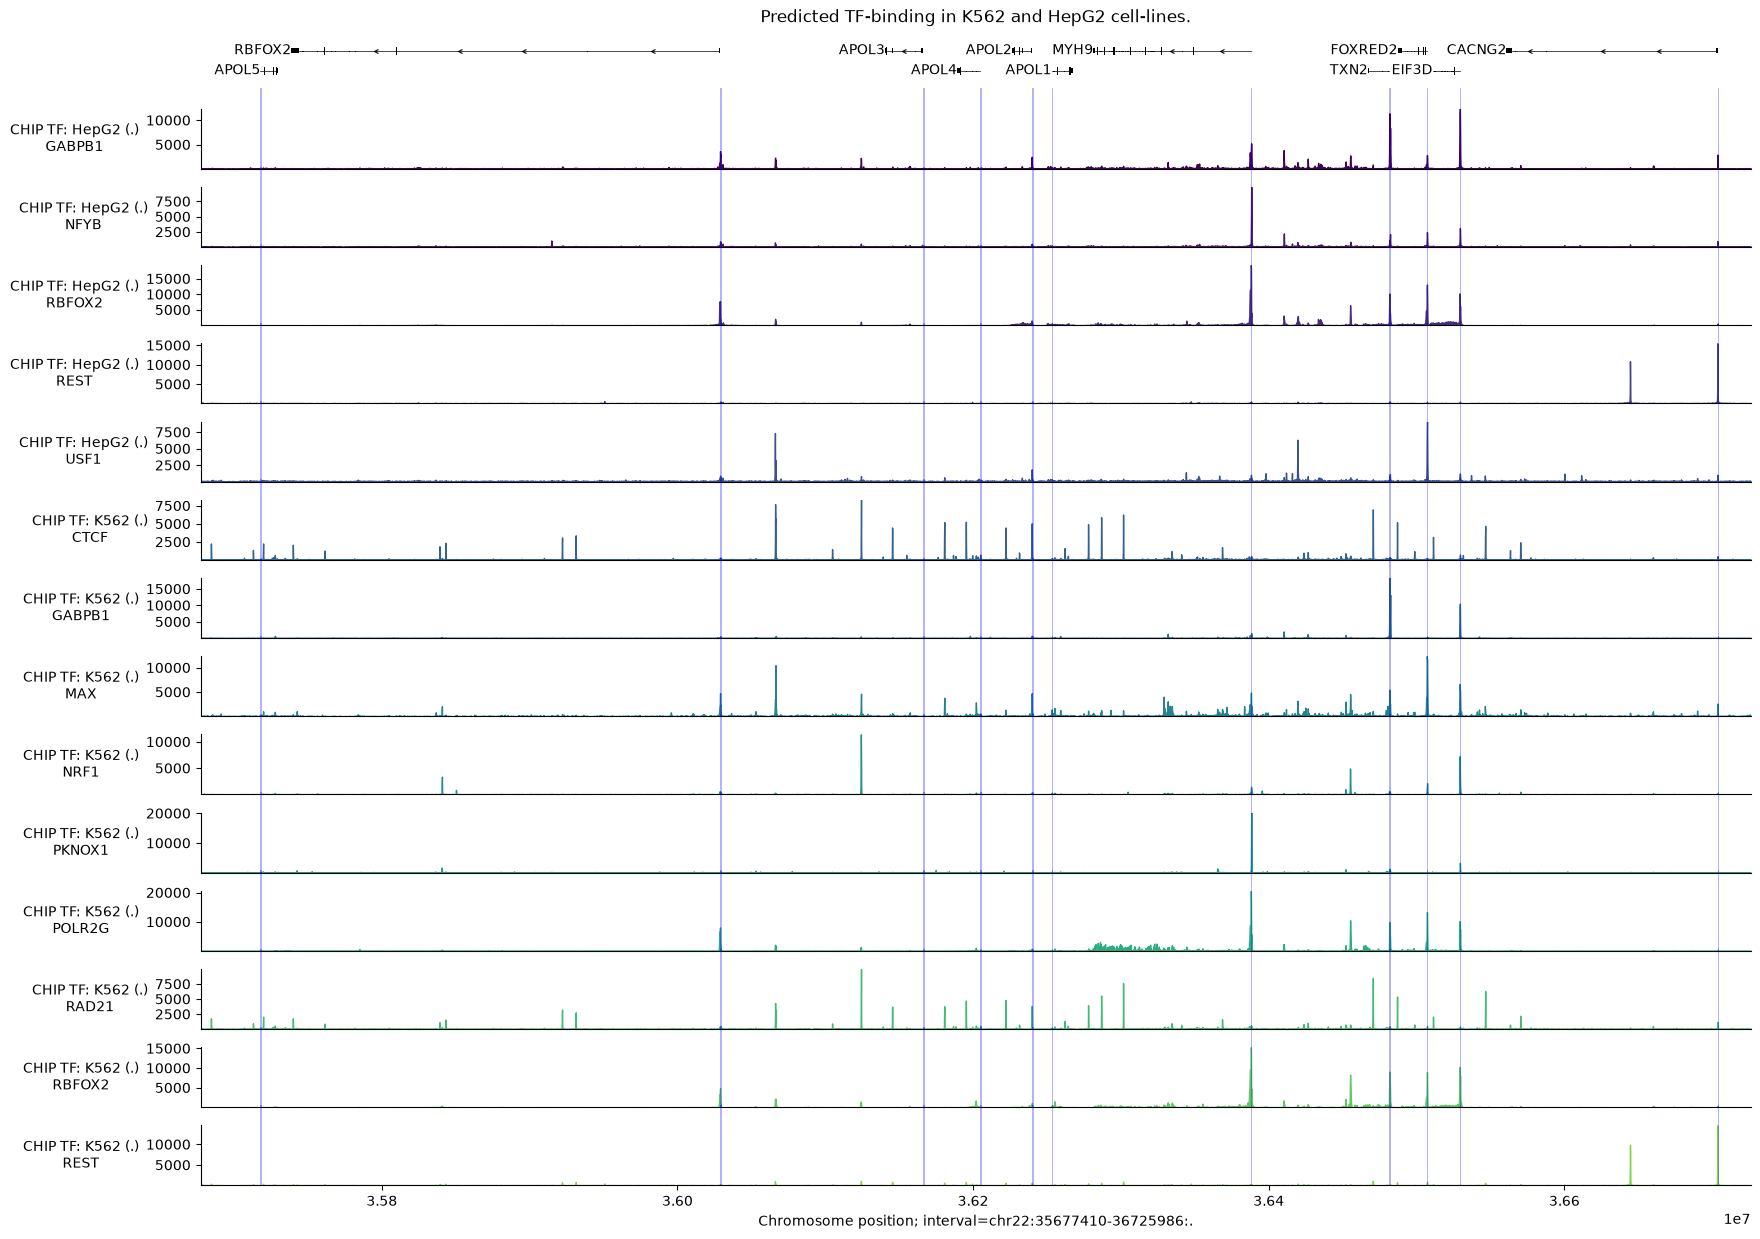

In [79]:
# Build plot.
plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output_filtered,
            ylabel_template=(
                'CHIP TF: {biosample_name} ({strand})\n{transcription_factor}'
            ),
            filled=True,
        ),
    ],
    interval=interval,
    title='Predicted TF-binding in K562 and HepG2 cell-lines.',
    despine_keep_bottom=True,
    annotations=[
        plot_components.IntervalAnnotation(
            tss_as_intervals, alpha=0.3, colors='blue'
        )
    ],
)
plt.show()

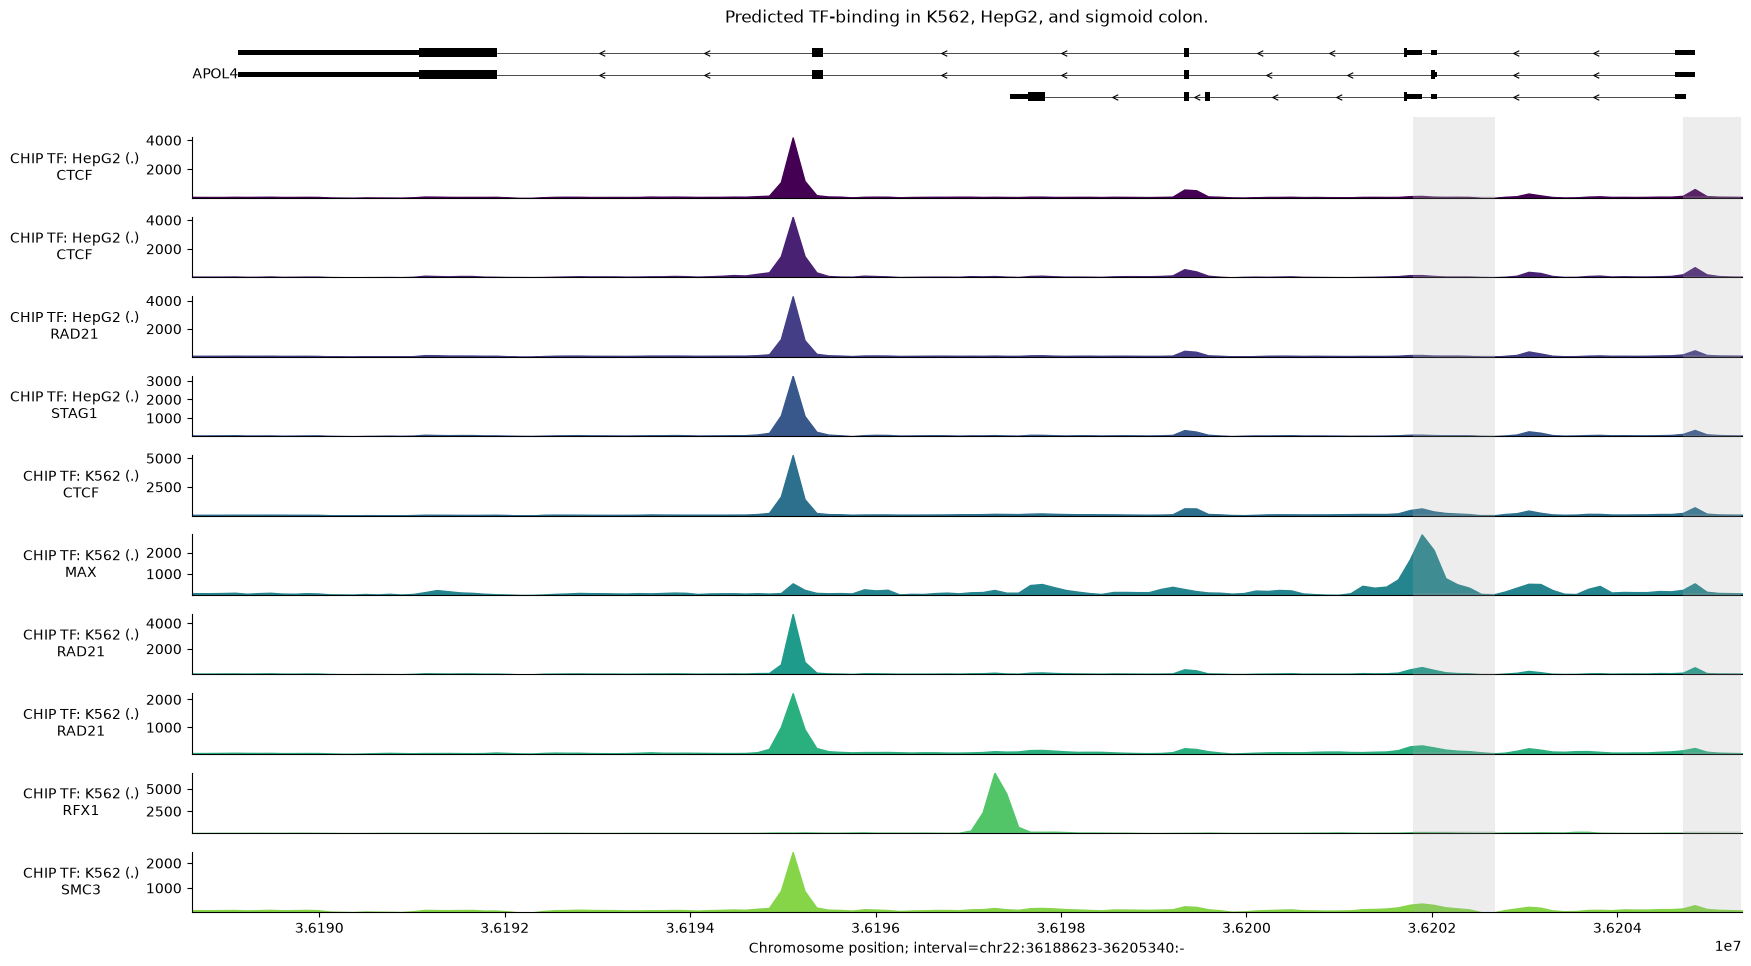

In [80]:
# Compute max predicted values per track in the APOL4 gene interval.
max_predictions = output.chip_tf.slice_by_interval(
    apol4_interval, match_resolution=True
).values.max(axis=0)

# Filter to the 10 tracks with the highest predictions.
output_filtered = output.chip_tf.filter_tracks(
    (max_predictions >= np.sort(max_predictions)[-10])
)

# Build plot.
plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.Tracks(
            tdata=output_filtered,
            ylabel_template=(
                'CHIP TF: {biosample_name} ({strand})\n{transcription_factor}'
            ),
            filled=True,
        ),
    ],
    interval=apol4_interval,
    annotations=[plot_components.IntervalAnnotation(promoter_intervals)],
    despine_keep_bottom=True,
    title='Predicted TF-binding in K562, HepG2, and sigmoid colon.',
)
plt.show()

In [81]:
ontology_terms = [
    'EFO:0002824',  # HCT116 colon carcinoma cell line.
]

output = dna_model.predict_interval(
    interval=interval,
    requested_outputs={dna_client.OutputType.CONTACT_MAPS},
    ontology_terms=ontology_terms,
)

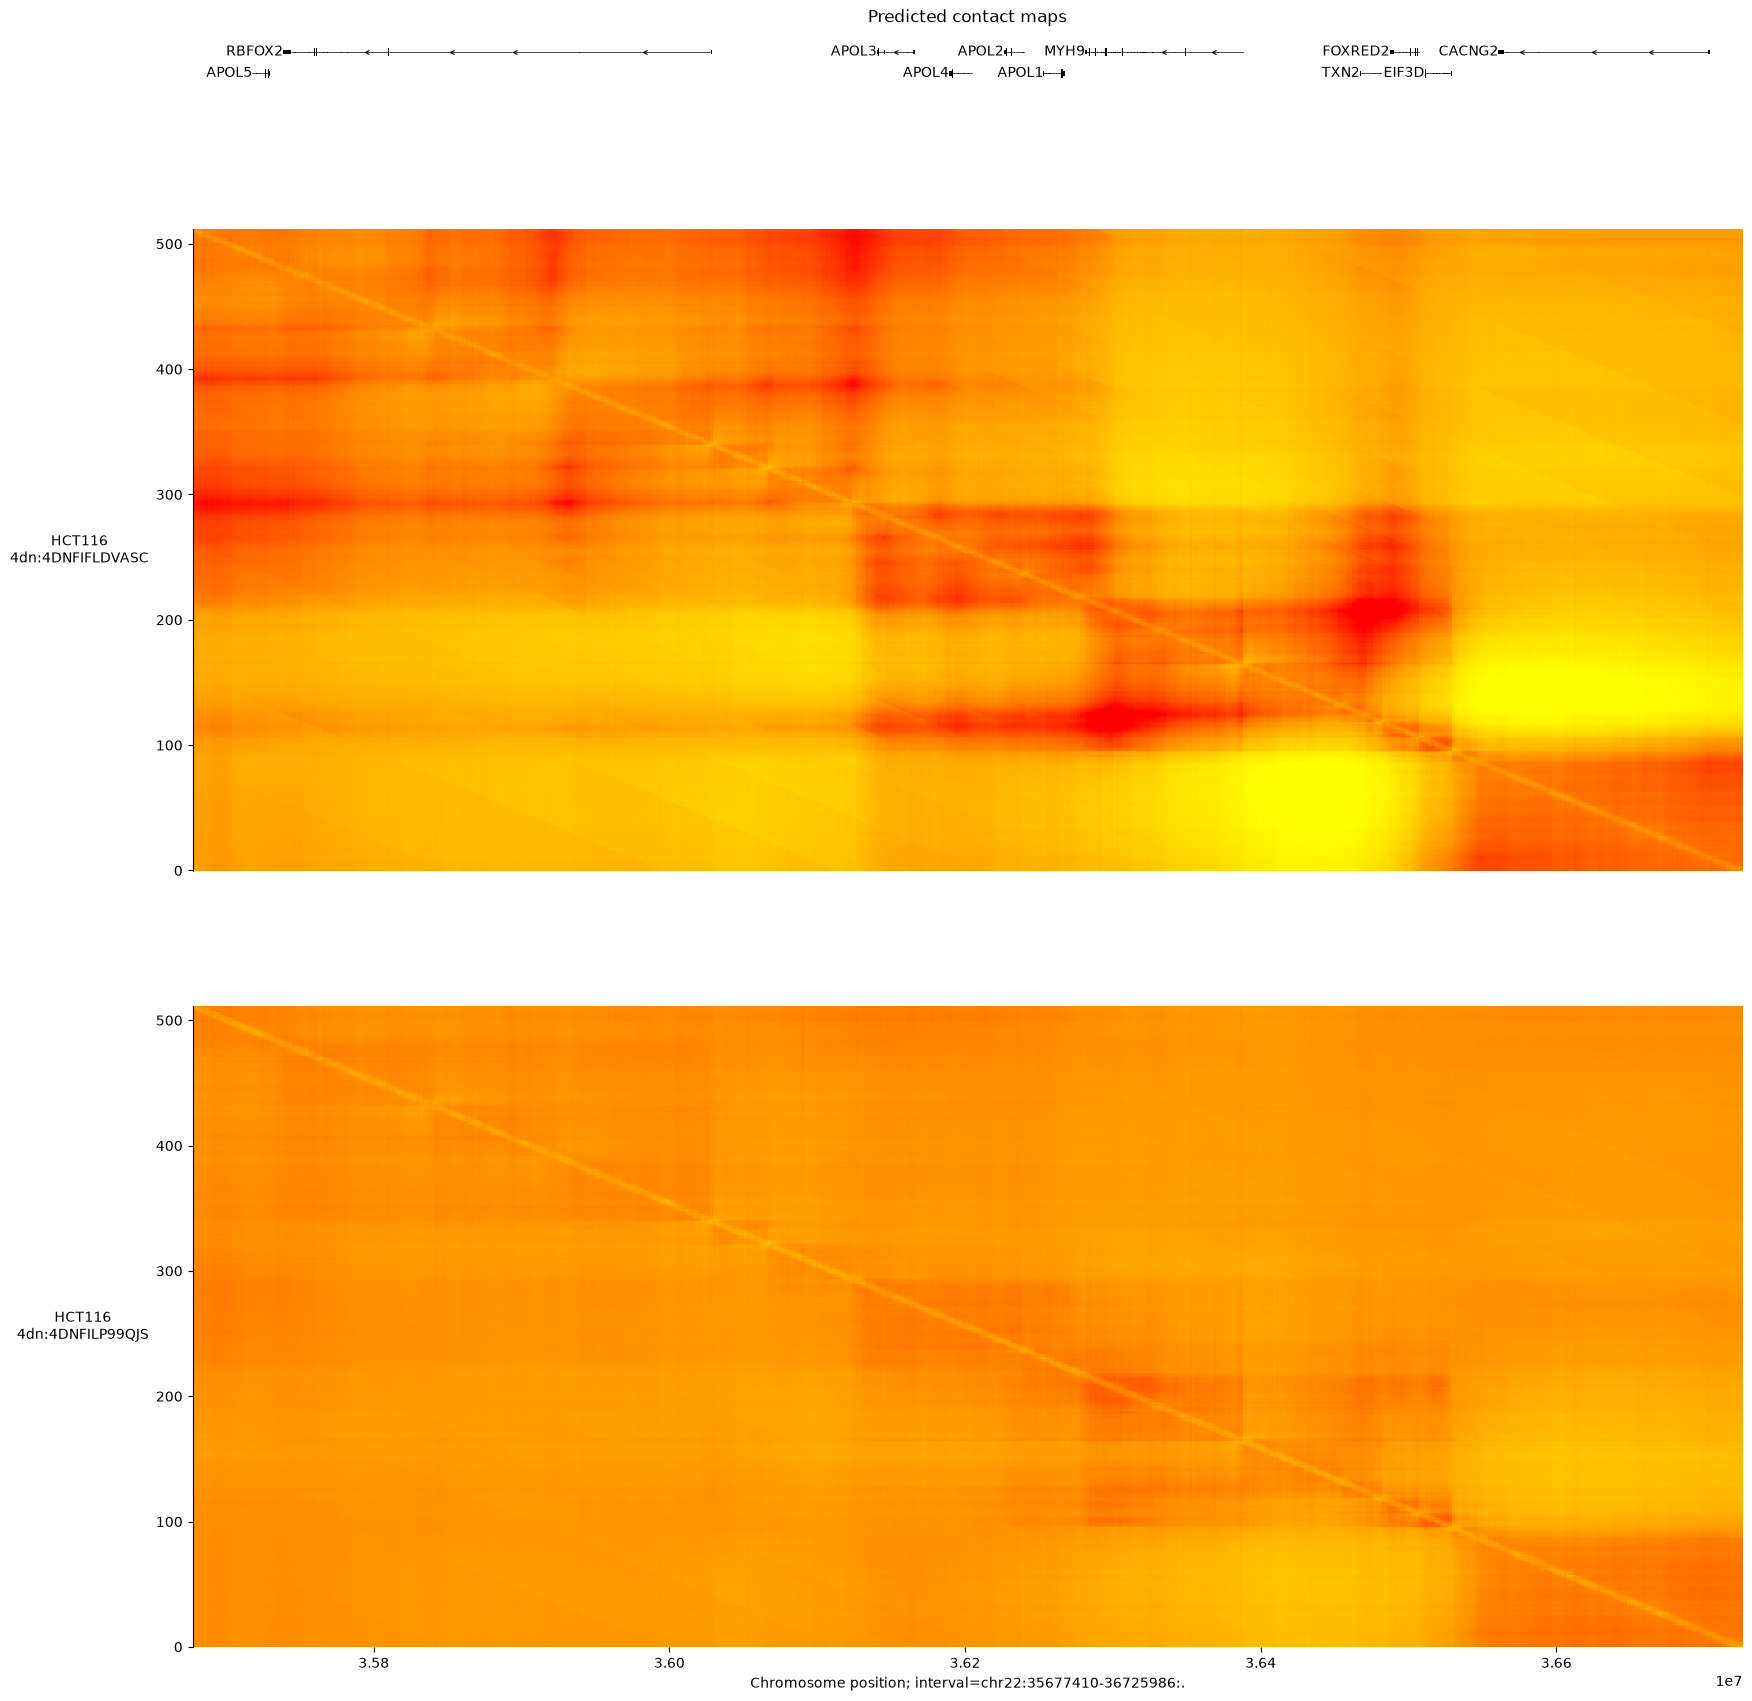

In [82]:
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.ContactMaps(
            tdata=output.contact_maps,
            ylabel_template='{biosample_name}\n{name}',
            cmap='autumn_r',
            vmax=1.0,
        ),
    ],
    interval=interval,
    title='Predicted contact maps',
)
plt.show()

# Scoring and visualizing a single variant

In [83]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation, genome, transcript, track_data
from alphagenome.models import dna_client, variant_scorers
from alphagenome.visualization import plot_components
import pandas as pd


# Load the model.
API_KEY = "***REMOVED***"

dna_model = dna_client.create(API_KEY)

HG38_GTF_FEATHER = (
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
MM10_GTF_FEATHER = (
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'mm10/gencode.vM23.annotation.gtf.gz.feather'
)

# Initialize an empty dictionary to serve as a variant effect prediction cache.
_prediction_cache = {}

_transcript_extractor_cache = {}

In [84]:
# @title Score variant { run: "auto" }
organism = 'human'  # @param ["human", "mouse"] {type:"string"}
organism_map = {
    'human': dna_client.Organism.HOMO_SAPIENS,
    'mouse': dna_client.Organism.MUS_MUSCULUS,
}
organism = organism_map[organism]

# @markdown Specify the variant:
variant_chromosome = 'chr22'  # @param { type:"string" }
variant_position = 36201698  # @param { type:"integer" }
variant_reference_bases = 'A'  # @param { type:"string" }
variant_alternate_bases = 'C'  # @param { type:"string" }

variant = genome.Variant(
    chromosome=variant_chromosome,
    position=variant_position,
    reference_bases=variant_reference_bases,
    alternate_bases=variant_alternate_bases,
)

# @markdown Specify length of sequence around variant to predict:
sequence_length = '1MB'  # @param ["2KB", "16KB", "100KB", "500KB", "1MB"] { type:"string" }
sequence_length = dna_client.SUPPORTED_SEQUENCE_LENGTHS[
    f'SEQUENCE_LENGTH_{sequence_length}'
]

# The input interval is derived from the variant (centered on it).
interval = variant.reference_interval.resize(sequence_length)

# @markdown Additional settings:
variant_scores = dna_model.score_variant(
    interval=interval,
    variant=variant,
    variant_scorers=list(variant_scorers.RECOMMENDED_VARIANT_SCORERS.values()),
)

df_scores = variant_scorers.tidy_scores(variant_scores)

download_predictions = False  # @param { type: "boolean" }
if download_predictions:
  df_scores.to_csv(f'{variant}_scores.csv', index=False)
  files.download(f'{variant}_scores.csv')

# @markdown Click `Filter` on the upper right hand side of the interactive dataframe and type a cell or tissue name like "brain" into the `Search by all fields box` to subset the variant scores to a specific tissue of interest:
columns = [
    c for c in df_scores.columns if c not in ['variant_id', 'scored_interval']
]
df_scores[columns]

,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,track_name,track_strand,...,biosample_type,biosample_life_stage,data_source,endedness,genetically_modified,transcription_factor,histone_mark,gtex_tissue,raw_score,quantile_score
0,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",CL:0000084 ATAC-seq,.,...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.102495,-0.977415
1,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",CL:0000100 ATAC-seq,.,...,in_vitro_differentiated_cells,adult,encode,paired,False,NaN,NaN,NaN,-0.003524,-0.151293
2,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",CL:0000236 ATAC-seq,.,...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,0.034877,0.800904
3,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",CL:0000623 ATAC-seq,.,...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.034184,-0.875283
4,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",CL:0000624 ATAC-seq,.,...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.113076,-0.971457
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36477,None,None,None,None,None,None,PROCAP,"CenterMaskScorer(requested_output=PROCAP, widt...",ENCSR182QNJ,-,...,cell_line,NaN,encode,NaN,False,NaN,NaN,NaN,4.118245,0.958945
36478,None,None,None,None,None,None,PROCAP,"CenterMaskScorer(requested_output=PROCAP, widt...",ENCSR740IPL,-,...,cell_line,NaN,encode,NaN,False,NaN,NaN,NaN,2135.385254,0.999070
36479,None,None,None,None,None,None,PROCAP,"CenterMaskScorer(requested_output=PROCAP, widt...",ENCSR797DEF,-,...,cell_line,NaN,encode,NaN,False,NaN,NaN,NaN,9.283513,0.974892
36480,None,None,None,None,None,None,PROCAP,"CenterMaskScorer(requested_output=PROCAP, widt...",ENCSR801ECP,-,...,primary_cell,NaN,encode,NaN,False,NaN,NaN,NaN,46.664753,0.989080


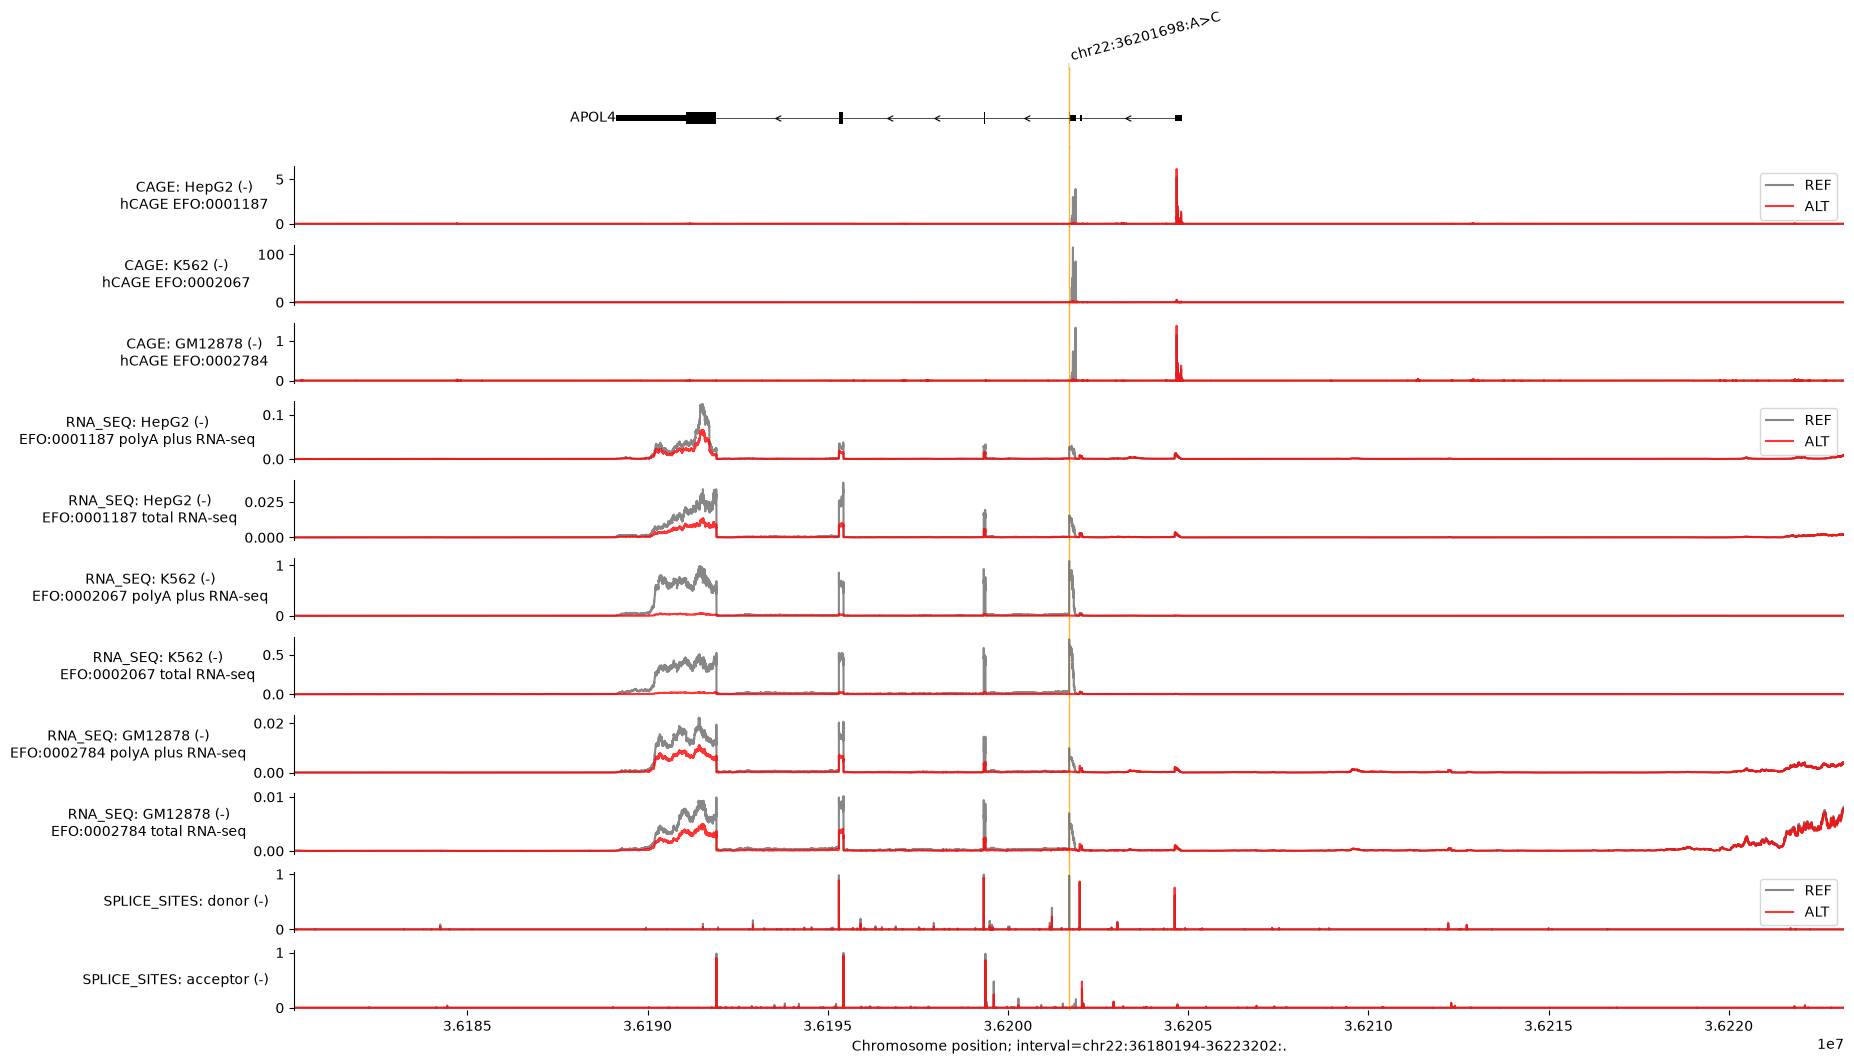

In [85]:
# @title Visualize variant effects { run: "auto" }
# @markdown We can also visualise the predicted effects of the variant by first predicting tracks for the REF and ALT alleles:

# @markdown Specify list of cell and tissue ontologies:
ontology_terms = ['EFO:0001187', 'EFO:0002067', 'EFO:0002784']  # @param

# @markdown Gene and transcript annotation options:
plot_gene_annotation = True  # @param { type: "boolean" }
plot_longest_transcript_only = True  # @param { type: "boolean" }

# @markdown Output types to plot (if present in output):
plot_rna_seq = True  # @param { type: "boolean" }
plot_cage = True  # @param { type: "boolean" }
plot_atac = False  # @param { type: "boolean" }
plot_dnase = False  # @param { type: "boolean" }
plot_chip_histone = False  # @param { type: "boolean" }
plot_chip_tf = False  # @param { type: "boolean" }
plot_splice_sites = True  # @param { type: "boolean" }
plot_splice_site_usage = False  # @param { type: "boolean" }
plot_contact_maps = False  # @param { type: "boolean" }
plot_splice_junctions = False  # @param { type: "boolean" }

# @markdown Option to filter tracks to only a specific DNA strand:
filter_to_positive_strand = False  # @param { type: "boolean" }
filter_to_negative_strand = True  # @param { type: "boolean" }
if filter_to_positive_strand and filter_to_negative_strand:
  raise ValueError(
      'Cannot specify both filter_to_positive_strand and '
      'filter_to_negative_strand.'
  )

# @markdown Specify a list of Transription Factors to select from CHIP_TF outputs e.g. ['IKZF1'].
# These must be contained in the 'transcription_factor' column of the CHIP_TF metadata.
transcription_factors = None  # @param

# @markdown Other visualization options:
ref_color = 'dimgrey'  # @param { type: "string" }
alt_color = 'red'  # @param { type: "string" }
ref_alt_colors = {'REF': ref_color, 'ALT': alt_color}
plot_interval_width = 43008 # @param { type: "slider", min: 2048, max: 1048576, step: 2048}
plot_interval_shift = 0 # @param { type: "slider", min: -524288, max: 524288, step: 2048}


# Load gene annotation.
if organism in _transcript_extractor_cache:
  transcript_extractor, longest_transcript_extractor = (
      _transcript_extractor_cache[organism]
  )
else:
  match organism:
    case dna_client.Organism.HOMO_SAPIENS:
      gtf_path = HG38_GTF_FEATHER
    case dna_client.Organism.MUS_MUSCULUS:
      gtf_path = MM10_GTF_FEATHER
    case _:
      raise ValueError(f'Unsupported organism: {organism}')

  gtf = pd.read_feather(gtf_path)

  # Filter to protein-coding genes and highly supported transcripts.
  gtf_transcript = gene_annotation.filter_transcript_support_level(
      gene_annotation.filter_protein_coding(gtf), ['1']
  )

  # Extractor for identifying transcripts in a region.
  transcript_extractor = transcript.TranscriptExtractor(gtf_transcript)

  # Also define an extractor that fetches only the longest transcript per gene.
  gtf_longest_transcript = gene_annotation.filter_to_longest_transcript(
      gtf_transcript
  )
  longest_transcript_extractor = transcript.TranscriptExtractor(
      gtf_longest_transcript
  )
  _transcript_extractor_cache[organism] = (
      transcript_extractor,
      longest_transcript_extractor,
  )


def _predict_variant_cached(
    interval, variant, organism, requested_outputs, ontology_terms
):
  """Cache wrapper of dna_model.predict_variant."""
  # Create a unique key from the function arguments.
  cache_key = (
      str(interval),
      str(variant),
      str(organism),
      tuple(requested_outputs),
      tuple(ontology_terms),
  )

  # Check if the result is already in the cache.
  if cache_key in _prediction_cache:
    return _prediction_cache[cache_key]

  # If not, compute the prediction and store it in the cache.
  result = dna_model.predict_variant(
      interval=interval,
      variant=variant,
      organism=organism,
      requested_outputs=requested_outputs,
      ontology_terms=ontology_terms,
  )
  _prediction_cache[cache_key] = result
  return result


output = _predict_variant_cached(
    interval=interval,
    variant=variant,
    organism=organism,
    requested_outputs=[*dna_client.OutputType],
    ontology_terms=ontology_terms,
)

# Filter to DNA strand if requested.
ref, alt = output.reference, output.alternate

if filter_to_positive_strand:
  ref = ref.filter_to_strand(strand='+')
  alt = alt.filter_to_strand(strand='+')
elif filter_to_negative_strand:
  ref = ref.filter_to_strand(strand='-')
  alt = alt.filter_to_strand(strand='-')

# Function to filter to TFs if requested.


def _maybe_filter_to_tfs(
    tdata: track_data.TrackData,
) -> track_data.TrackData | None:
  if not plot_chip_tf:
    return tdata

  if plot_chip_tf and (transcription_factors is not None):
    if not isinstance(transcription_factors, list):
      raise ValueError('TFs must be input as a list of strings.')
    if not isinstance(transcription_factors[0], str):
      raise ValueError('TFs must be input as a list of strings.')

  if transcription_factors is None:
    return tdata

  tf_rows = tdata.metadata.index[
      tdata.metadata['transcription_factor'].isin(transcription_factors)
  ]
  if not tf_rows.any():
    print(
        f'No tracks found for specified transcription factors and'
        f' ontology_terms.'
    )
    return None
  missing_tfs = set(transcription_factors).difference(
      set(tdata.metadata['transcription_factor'])
  )
  if missing_tfs:
    print(
        f'Could not find tracks in chip_tf outputs corresponding to the'
        f' following requested TFs'
    )
  return tdata.select_tracks_by_index(tf_rows)


# Build plot.
components = []

# Gene and transcript annotation.
if plot_gene_annotation:
  if plot_longest_transcript_only:
    transcripts = longest_transcript_extractor.extract(interval)
  else:
    transcripts = transcript_extractor.extract(interval)
  components.append(plot_components.TranscriptAnnotation(transcripts))


# Individual output type plots.
plot_map = {
    'plot_atac': (ref.atac, alt.atac, 'ATAC'),
    'plot_cage': (ref.cage, alt.cage, 'CAGE'),
    'plot_chip_histone': (ref.chip_histone, alt.chip_histone, 'CHIP_HISTONE'),
    'plot_chip_tf': (
        _maybe_filter_to_tfs(ref.chip_tf),
        _maybe_filter_to_tfs(alt.chip_tf),
        'CHIP_TF',
    ),
    'plot_contact_maps': (ref.contact_maps, alt.contact_maps, 'CONTACT_MAPS'),
    'plot_dnase': (ref.dnase, alt.dnase, 'DNASE'),
    'plot_rna_seq': (ref.rna_seq, alt.rna_seq, 'RNA_SEQ'),
    'plot_splice_junctions': (
        ref.splice_junctions,
        alt.splice_junctions,
        'SPLICE_JUNCTIONS',
    ),
    'plot_splice_sites': (ref.splice_sites, alt.splice_sites, 'SPLICE_SITES'),
    'plot_splice_site_usage': (
        ref.splice_site_usage,
        alt.splice_site_usage,
        'SPLICE_SITE_USAGE',
    ),
}

for key, (ref_data, alt_data, output_type) in plot_map.items():
  if eval(key) and ref_data is not None and ref_data.values.shape[-1] == 0:
    print(
        f'Requested plot for output {output_type} but no tracks exist in'
        ' output. This is likely because this output does not exist for your'
        ' ontologies or requested DNA strand.'
    )
  if eval(key) and ref_data and alt_data:
    match output_type:
      case 'CHIP_HISTONE':
        ylabel_template = (
            f'{output_type}: {{biosample_name}} ({{strand}})\n{{histone_mark}}'
        )
      case 'CHIP_TF':
        ylabel_template = (
            f'{output_type}: {{biosample_name}}'
            ' ({strand})\n{transcription_factor}'
        )
      case 'CONTACT_MAPS':
        ylabel_template = f'{output_type}: {{biosample_name}} ({{strand}})'
      case 'SPLICE_SITES':
        ylabel_template = f'{output_type}: {{name}} ({{strand}})'
      case _:
        ylabel_template = (
            f'{output_type}: {{biosample_name}} ({{strand}})\n{{name}}'
        )

    if output_type == 'CONTACT_MAPS':
      component = plot_components.ContactMapsDiff(
          tdata=alt_data - ref_data,
          ylabel_template=ylabel_template,
      )
      components.append(component)
    elif output_type == 'SPLICE_JUNCTIONS':
      ref_plot = plot_components.Sashimi(
          ref_data,
          ylabel_template='REF: ' + ylabel_template,
      )
      alt_plot = plot_components.Sashimi(
          alt_data,
          ylabel_template='ALT: ' + ylabel_template,
      )
      components.extend([ref_plot, alt_plot])
    else:
      component = plot_components.OverlaidTracks(
          tdata={'REF': ref_data, 'ALT': alt_data},
          colors=ref_alt_colors,
          ylabel_template=ylabel_template,
      )
      components.append(component)

if plot_interval_width > interval.width:
  raise ValueError(
      f'plot_interval_width ({plot_interval_width}) must be less than '
      f'interval.width ({interval.width}).'
  )

plot = plot_components.plot(
    components=components,
    interval=interval.shift(plot_interval_shift).resize(plot_interval_width),
    annotations=[
        plot_components.VariantAnnotation([variant]),
    ],
)

# Navigating data ontologies

In [86]:
from alphagenome import colab_utils
from alphagenome.models import dna_client
import pandas as pd



In [87]:
output_metadata = dna_model.output_metadata(
    dna_client.Organism.HOMO_SAPIENS
).concatenate()

In [88]:
output_metadata

,name,strand,Assay title,ontology_curie,biosample_name,biosample_type,biosample_life_stage,data_source,endedness,genetically_modified,nonzero_mean,output_type,gtex_tissue,histone_mark,transcription_factor
0,CL:0000084 ATAC-seq,.,ATAC-seq,CL:0000084,T-cell,primary_cell,adult,encode,paired,False,0.739741,OutputType.ATAC,NaN,NaN,NaN
1,CL:0000100 ATAC-seq,.,ATAC-seq,CL:0000100,motor neuron,in_vitro_differentiated_cells,adult,encode,paired,False,0.273136,OutputType.ATAC,NaN,NaN,NaN
2,CL:0000236 ATAC-seq,.,ATAC-seq,CL:0000236,B cell,primary_cell,adult,encode,paired,False,4.700081,OutputType.ATAC,NaN,NaN,NaN
3,CL:0000623 ATAC-seq,.,ATAC-seq,CL:0000623,natural killer cell,primary_cell,adult,encode,paired,False,0.938715,OutputType.ATAC,NaN,NaN,NaN
4,CL:0000624 ATAC-seq,.,ATAC-seq,CL:0000624,"CD4-positive, alpha-beta T cell",primary_cell,adult,encode,paired,False,4.365206,OutputType.ATAC,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,ENCSR182QNJ,-,PRO-cap,EFO:0001099,Caco-2,cell_line,NaN,encode,NaN,False,14.002803,OutputType.PROCAP,NaN,NaN,NaN
8,ENCSR740IPL,-,PRO-cap,EFO:0002067,K562,cell_line,NaN,encode,NaN,False,15.765458,OutputType.PROCAP,NaN,NaN,NaN
9,ENCSR797DEF,-,PRO-cap,EFO:0002819,Calu3,cell_line,NaN,encode,NaN,False,12.281321,OutputType.PROCAP,NaN,NaN,NaN
10,ENCSR801ECP,-,PRO-cap,CL:0002618,endothelial cell of umbilical vein,primary_cell,NaN,encode,NaN,False,13.973692,OutputType.PROCAP,NaN,NaN,NaN


In [89]:
# Count human tracks
human_tracks = (
    dna_model.output_metadata(dna_client.Organism.HOMO_SAPIENS)
    .concatenate()
    .groupby('output_type')
    .size()
    .rename('# Human tracks')
)

# Count mouse tracks
mouse_tracks = (
    dna_model.output_metadata(dna_client.Organism.MUS_MUSCULUS)
    .concatenate()
    .groupby('output_type')
    .size()
    .rename('# Mouse tracks')
)

pd.concat([human_tracks, mouse_tracks], axis=1).astype(pd.Int64Dtype())

,# Human tracks,# Mouse tracks
output_type,,
OutputType.ATAC,167,18
OutputType.CAGE,546,188
OutputType.DNASE,305,67
OutputType.RNA_SEQ,667,173
OutputType.CHIP_HISTONE,1116,183
OutputType.CHIP_TF,1617,127
OutputType.SPLICE_SITES,4,4
OutputType.SPLICE_SITE_USAGE,734,180
OutputType.SPLICE_JUNCTIONS,367,90


# Batch variant scoring

In [90]:
# @title Setup and imports.

from io import StringIO
from alphagenome import colab_utils
from alphagenome.data import genome
from alphagenome.models import dna_client, variant_scorers
#from google.colab import data_table, files
import pandas as pd
from tqdm import tqdm

#data_table.enable_dataframe_formatter()

# Load the model.
#dna_model = dna_client.create(colab_utils.get_api_key())

In [91]:
API_KEY = "***REMOVED***"

dna_model = dna_client.create(API_KEY)

In [92]:
# @title Score batch of variants.

# Load VCF file containing variants.
vcf_file = 'placeholder'  # @param

# We provide an example list of variants to illustrate.
vcf_file = """variant_id\tCHROM\tPOS\tREF\tALT
chr3_58394738_A_T_b38\tchr3\t58394738\tA\tT
chr8_28520_G_C_b38\tchr8\t28520\tG\tC
chr16_636337_G_A_b38\tchr16\t636337\tG\tA
chr16_1135446_G_T_b38\tchr16\t1135446\tG\tT
"""

vcf = pd.read_csv(StringIO(vcf_file), sep='\t')

required_columns = ['variant_id', 'CHROM', 'POS', 'REF', 'ALT']
for column in required_columns:
  if column not in vcf.columns:
    raise ValueError(f'VCF file is missing required column: {column}.')

organism = 'human'  # @param ["human", "mouse"] {type:"string"}

# @markdown Specify length of sequence around variants to predict:
sequence_length = '1MB'  # @param ["16KB", "100KB", "500KB", "1MB"] { type:"string" }
sequence_length = dna_client.SUPPORTED_SEQUENCE_LENGTHS[
    f'SEQUENCE_LENGTH_{sequence_length}'
]

# @markdown Specify which scorers to use to score your variants:
score_rna_seq = True  # @param { type: "boolean"}
score_cage = True  # @param { type: "boolean" }
score_procap = True  # @param { type: "boolean" }
score_atac = True  # @param { type: "boolean" }
score_dnase = True  # @param { type: "boolean" }
score_chip_histone = True  # @param { type: "boolean" }
score_chip_tf = True  # @param { type: "boolean" }
score_polyadenylation = True  # @param { type: "boolean" }
score_splice_sites = True  # @param { type: "boolean" }
score_splice_site_usage = True  # @param { type: "boolean" }
score_splice_junctions = True  # @param { type: "boolean" }

# @markdown Other settings:
download_predictions = False  # @param { type: "boolean" }

# Parse organism specification.
organism_map = {
    'human': dna_client.Organism.HOMO_SAPIENS,
    'mouse': dna_client.Organism.MUS_MUSCULUS,
}
organism = organism_map[organism]

# Parse scorer specification.
scorer_selections = {
    'rna_seq': score_rna_seq,
    'cage': score_cage,
    'procap': score_procap,
    'atac': score_atac,
    'dnase': score_dnase,
    'chip_histone': score_chip_histone,
    'chip_tf': score_chip_tf,
    'polyadenylation': score_polyadenylation,
    'splice_sites': score_splice_sites,
    'splice_site_usage': score_splice_site_usage,
    'splice_junctions': score_splice_junctions,
}

all_scorers = variant_scorers.RECOMMENDED_VARIANT_SCORERS
selected_scorers = [
    all_scorers[key]
    for key in all_scorers
    if scorer_selections.get(key.lower(), False)
]

# Remove any scorers or output types that are not supported for the chosen organism.
unsupported_scorers = [
    scorer
    for scorer in selected_scorers
    if (
        organism.value
        not in variant_scorers.SUPPORTED_ORGANISMS[scorer.base_variant_scorer]
    )
    | (
        (scorer.requested_output == dna_client.OutputType.PROCAP)
        & (organism == dna_client.Organism.MUS_MUSCULUS)
    )
]
if len(unsupported_scorers) > 0:
  print(
      f'Excluding {unsupported_scorers} scorers as they are not supported for'
      f' {organism}.'
  )
  for unsupported_scorer in unsupported_scorers:
    selected_scorers.remove(unsupported_scorer)


# Score variants in the VCF file.
results = []

for i, vcf_row in tqdm(vcf.iterrows(), total=len(vcf)):
  variant = genome.Variant(
      chromosome=str(vcf_row.CHROM),
      position=int(vcf_row.POS),
      reference_bases=vcf_row.REF,
      alternate_bases=vcf_row.ALT,
      name=vcf_row.variant_id,
  )
  interval = variant.reference_interval.resize(sequence_length)

  variant_scores = dna_model.score_variant(
      interval=interval,
      variant=variant,
      variant_scorers=selected_scorers,
      organism=organism,
  )
  results.append(variant_scores)

df_scores = variant_scorers.tidy_scores(results)

if download_predictions:
  df_scores.to_csv('variant_scores.csv', index=False)
  files.download('variant_scores.csv')

df_scores

100%|██████████| 4/4 [00:04<00:00,  1.23s/it]


,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,...,biosample_type,biosample_life_stage,data_source,endedness,genetically_modified,transcription_factor,histone_mark,gtex_tissue,raw_score,quantile_score
0,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.003932,-0.216733
1,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",...,in_vitro_differentiated_cells,adult,encode,paired,False,NaN,NaN,NaN,0.010877,0.216733
2,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.007336,-0.326413
3,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.011755,-0.519734
4,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.010606,-0.441693
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115117,chr16:1135446:G>T,chr16:611158-1659734:.,ENSG00000292423,ENSG00000292423,lncRNA,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,tissue,adult,gtex,paired,False,NaN,NaN,Skin_Not_Sun_Exposed_Suprapubic,-0.000835,-0.531989
115118,chr16:1135446:G>T,chr16:611158-1659734:.,ENSG00000292430,ENSG00000292430,lncRNA,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,tissue,adult,gtex,paired,False,NaN,NaN,Skin_Not_Sun_Exposed_Suprapubic,-0.001656,-0.746766
115119,chr16:1135446:G>T,chr16:611158-1659734:.,ENSG00000292431,ENSG00000292431,lncRNA,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,tissue,adult,gtex,paired,False,NaN,NaN,Skin_Not_Sun_Exposed_Suprapubic,0.000096,0.134700
115120,chr16:1135446:G>T,chr16:611158-1659734:.,ENSG00000292432,ENSG00000292432,lncRNA,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,tissue,adult,gtex,paired,False,NaN,NaN,Skin_Not_Sun_Exposed_Suprapubic,0.000776,0.519734


In [93]:
# Examine just the effects of the variants on T-cells.
columns = [c for c in df_scores.columns if c != 'ontology_curie']
df_scores[(df_scores['ontology_curie'] == 'CL:0000084')][columns]

,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,...,biosample_type,biosample_life_stage,data_source,endedness,genetically_modified,transcription_factor,histone_mark,gtex_tissue,raw_score,quantile_score
0,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,ATAC,"CenterMaskScorer(requested_output=ATAC, width=...",...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.003932,-0.216733
168,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,DNASE,"CenterMaskScorer(requested_output=DNASE, width...",...,primary_cell,adult,encode,paired,False,NaN,NaN,NaN,-0.031748,-0.632384
2109,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,CHIP_HISTONE,CenterMaskScorer(requested_output=CHIP_HISTONE...,...,primary_cell,adult,encode,single,False,NaN,H3K27ac,NaN,0.000981,0.101294
2110,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,CHIP_HISTONE,CenterMaskScorer(requested_output=CHIP_HISTONE...,...,primary_cell,adult,encode,single,False,NaN,H3K27me3,NaN,-0.002489,-0.248775
2111,chr3:58394738:A>T,chr3:57870450-58919026:.,None,None,None,None,None,None,CHIP_HISTONE,CenterMaskScorer(requested_output=CHIP_HISTONE...,...,primary_cell,adult,encode,single,False,NaN,H3K36me3,NaN,-0.000752,-0.200530
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78417,chr16:1135446:G>T,chr16:611158-1659734:.,ENSG00000292423,ENSG00000292423,lncRNA,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,primary_cell,adult,encode,single,False,NaN,NaN,,-0.000682,-0.600902
78418,chr16:1135446:G>T,chr16:611158-1659734:.,ENSG00000292430,ENSG00000292430,lncRNA,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,primary_cell,adult,encode,single,False,NaN,NaN,,0.000080,0.295816
78419,chr16:1135446:G>T,chr16:611158-1659734:.,ENSG00000292431,ENSG00000292431,lncRNA,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,primary_cell,adult,encode,single,False,NaN,NaN,,0.000012,0.134700
78420,chr16:1135446:G>T,chr16:611158-1659734:.,ENSG00000292432,ENSG00000292432,lncRNA,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,primary_cell,adult,encode,single,False,NaN,NaN,,-0.006636,-0.989576


In [94]:
import os
from alphagenome.atlas import atlas
from alphagenome.data import genome

API_KEY = "***REMOVED***"

client = atlas.create(API_KEY)
print(client.scorer_metadata().keys())            # see scorer names first

variants = [genome.Variant.from_str(v) for v in ["chr11:5225488:A>T", "chr9:128225994:G>A"]]
#res = client.query_variants(variants, requested_scorers=[...])  # names from scorer_metadata()


variants

dict_keys(['AVI_SCORE', 'AVI_SCORE_FEATURE_IMPORTANCE', 'AVI_SCORE_MODEL_FEATURES', 'CHIP_HISTONE_ACTIVE', 'ATAC_ACTIVE', 'CAGE_ACTIVE', 'CHIP_TF_ACTIVE', 'DNASE_ACTIVE', 'PROCAP_ACTIVE', 'CHIP_HISTONE', 'ATAC', 'CAGE', 'CHIP_TF', 'DNASE', 'PROCAP', 'CONTACT_MAPS', 'SPLICE_SITES', 'SPLICE_SITE_USAGE', 'RNA_SEQ_ACTIVE', 'RNA_SEQ', 'POLYADENYLATION', 'SPLICE_JUNCTIONS'])


[Variant(chromosome='chr11', position=5225488, reference_bases='A', alternate_bases='T', name=''),
 Variant(chromosome='chr9', position=128225994, reference_bases='G', alternate_bases='A', name='')]